# Career Preparedness

## Problem Brief
To understand **what drives “career preparedness”** among respondents and how these drivers **vary across people and regions**. The dataset (Excel with two sheets, two-row headers).

I use three blocks of inputs:
- **Explicit (Likert)**, what people say about their preparedness,
- **Implicit (reaction-time) measures**, quick/automatic responses,
- **Demographics/region**, and
- **Preparedness** indicators.

## Objective (What this analysis delivers)
1. **Define & align targets of preparedness**  
   – Continuous score (primary), with optional binary/ordinal variants for sensitivity checks.

2. **Diagnose global drivers**  
   – Build comparable models (Linear, Random Forest, XGBoost/HGB) to explain preparedness with **explicit, implicit, and combined** features; select the most reliable model (good R², no over/underfitting).

3. **Contrast explicit vs. implicit signals**  
   – Correlate measures, compute **discrepancies (Implicit − Explicit)**, and test their **incremental value (ΔR² / ΔAUC)**.

4. **Uncover regional differences**  
   – Fit per-country/region models (where N is sufficient) and map **which factors matter where**.

5. **Segment respondents** (Low / Medium / High) derived from the continuous scores for action.
   – Cluster on factor composites to identify actionable **personas** (e.g., “Confident but Unskilled”, “Anxious but Capable”).

6. **Communicate for decisions**  
   – Produce simple, slide-ready visuals (bar charts, heatmaps, cluster maps) and **recommend interventions** (skills training, wellbeing support, region-specific program design).

**Success criteria:** interpretable drivers, stable validation metrics, evidence of incremental value from implicit data, clear segment profiles, and practical recommendations.

---

All results use **cross‑validation** and simple, readable visuals.

---
---

In [1]:
# import libraries

import os, re, json, math, warnings, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
# Corrected import statement
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, roc_auc_score, brier_score_loss, average_precision_score, precision_recall_curve
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.optimize import linear_sum_assignment
from sklearn.calibration import CalibratedClassifierCV, calibration_curve



# Optional libraries (graceful fallback)
try:
    from xgboost import XGBRegressor, XGBClassifier
    XGB_AVAILABLE = True  # define ML model
except Exception as e:
    from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
    XGB_AVAILABLE = False
    warnings.warn(f'XGBoost not available ({e}); using HistGradientBoosting as a proxy.')

try:
    import shap
    SHAP_AVAILABLE = True
except Exception as e:
    SHAP_AVAILABLE = False
    warnings.warn(f'SHAP not available ({e}); SHAP plots will be skipped.')

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

pd.set_option("display.max_columns", 200)
warnings.filterwarnings("ignore")

#OUT_DIR = "/content/drive/MyDrive/cowrydsinterviewinvitationtaskdetails/Task_1"
#Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

#print("Environment ready. Outputs ->", OUT_DIR)

file_path = Path(
    r"C:\Users\ifenn\OneDrive\Desktop\Projects\Career_Preparedness\task1_enriched.csv"
)

df = pd.read_csv(file_path)

# Save notebook outputs in an outputs folder next to the CSV.
output_dir = file_path.parent / "outputs"
output_dir.mkdir(exist_ok=True)
OUT_DIR = str(output_dir)

print(f"Loaded {len(df):,} rows from {file_path.name}")
print(f"Outputs will be saved in {OUT_DIR}")
df.head()

Loaded 4,212 rows from task1_enriched.csv
Outputs will be saved in C:\Users\ifenn\OneDrive\Desktop\Projects\Career_Preparedness\outputs


,Batch Group,Gender,Age,Personality factors,Personality factors.1,Personality factors.2,Personality factors.3,Personality factors.4,Personality factors.5,Personality factors.6,Personality factors.7,Personality factors.8,Personality factors.9,Preparedness levels,Qualitative reasons,Emotional Likert explicit scores,Emotional Likert explicit scores.1,Emotional Likert explicit scores.2,Emotional Likert explicit scores.3,Emotional Likert explicit scores.4,Emotional Likert explicit scores.5,Emotional Likert explicit scores.6,Emotional Likert explicit scores.7,Emotional Likert explicit scores.8,Emotional Likert explicit scores.9,Emotional Likert explicit scores.10,Emotional Likert explicit scores.11,Emotional Likert explicit scores.12,Emotional Likert explicit scores.13,Emotional Likert explicit scores.14,Workplace / functional Likert explicit scores,Workplace / functional Likert explicit scores.1,Workplace / functional Likert explicit scores.2,Workplace / functional Likert explicit scores.3,Workplace / functional Likert explicit scores.4,Workplace / functional Likert explicit scores.5,Workplace / functional Likert explicit scores.6,Workplace / functional Likert explicit scores.7,Workplace / functional Likert explicit scores.8,Workplace / functional Likert explicit scores.9,Workplace / functional Likert explicit scores.10,Emotional Fast Choice implicit scores,Emotional Fast Choice implicit scores.1,Emotional Fast Choice implicit scores.2,Emotional Fast Choice implicit scores.3,Emotional Fast Choice implicit scores.4,Emotional Fast Choice implicit scores.5,Emotional Fast Choice implicit scores.6,Emotional Fast Choice implicit scores.7,Emotional Fast Choice implicit scores.8,Emotional Fast Choice implicit scores.9,Emotional Fast Choice implicit scores.10,Emotional Fast Choice implicit scores.11,Emotional Fast Choice implicit scores.12,Emotional Fast Choice implicit scores.13,Emotional Fast Choice implicit scores.14,Workplace / functional Fast choice implicit scores,Workplace / functional Fast choice implicit scores.1,Workplace / functional Fast choice implicit scores.2,Workplace / functional Fast choice implicit scores.3,Workplace / functional Fast choice implicit scores.4,Workplace / functional Fast choice implicit scores.5,Workplace / functional Fast choice implicit scores.6,Workplace / functional Fast choice implicit scores.7,Workplace / functional Fast choice implicit scores.8,Workplace / functional Fast choice implicit scores.9,Workplace / functional Fast choice implicit scores.10
0,Unnamed: 0_level_1,Unnamed: 1_level_1,Unnamed: 2_level_1,"Extraverted, Enthusiastic.","Critical, Quarrelsome.","Dependable, Self-Disciplined.","Anxious, Easily Upset.","Open To New Experiences, Complex.","Sympathetic, Warm.","Disorganized, Careless.","Reserved, Quiet.","Calm, Emotionally Stable.","Conventional, Uncreative.",Unnamed: 13_level_1,Unnamed: 14_level_1,Emotional Likert.Lbal Anx,Emotional Likert.Lbal Sat,Emotional Likert.Lcnt Com,Emotional Likert.Lcnt Psy,Emotional Likert.Lcon Inc,Emotional Likert.Lcon Soc,Emotional Likert.Lcont Con,Emotional Likert.Lcont Imp,Emotional Likert.Lgen,Emotional Likert.Ljou Opt,Emotional Likert.Ljou Pro,Emotional Likert.Lres Fin,Emotional Likert.Lres Ski,Emotional Likert.Ltra Aut,Emotional Likert.Ltra Des,Functional Likert.Lcarprom D,Functional Likert.Lcollea,Functional Likert.Lenjhyb,Functional Likert.Lexcess Wk,Functional Likert.Lfin Lair,Functional Likert.Llearn Dev,Functional Likert.Lmean Full,Functional Likert.Lpoorman,Functional Likert.Ltoxic,Functional Likert.Luse Skills,Functional Likert.Lwellcomp,Emotional Statements.Fbal Anx,Emotional Statements.Fbal Sat,Emotional Statements.Fcnt Com,Emotional Statements.Fcnt Psy,Emotional Statements.Fcon Inc,Emotional Statements.Fcon Soc,Emotional Statements.Fcont Con,Emotional Statements.Fcont Imp,Emotional Statements.Fgen,Emotional Statements.Fjou Opt,Emotional Statements.Fjou Pro,Emotional Statements.Fres Fin,Emotional Statements.Fres Ski,Emotional Statements.Ftra Au

## Data Path & Load Helpers

In [2]:
# Load the Excel file into a pandas DataFrame

DATA_PATH = file_path
print("Using DATA_PATH:", DATA_PATH)

# Use both header rows so the survey labels become column names.
data = pd.read_csv(DATA_PATH, header=[0, 1])

data_shape = data.shape
print("Data shape:", data_shape)

display(data.sample(10, random_state=42))

Using DATA_PATH: C:\Users\ifenn\OneDrive\Desktop\Projects\Career_Preparedness\task1_enriched.csv
Data shape: (4211, 67)


Batch Group             Gender                Age  \
     Unnamed: 0_level_1 Unnamed: 1_level_1 Unnamed: 2_level_1   
96               DE Fin               Male              25-40   
3305          US Pharma               Male              18-24   
811             FR Tech             Female              41-64   
463             FR Tech             Female              18-24   
2303             SP Fin               Male              25-40   
2751          UK Energy               Male              41-64   
2245             SP Fin               Male              25-40   
862             FR Tech             Female              18-24   
2827          UK Energy             Female              41-64   
3025          UK Energy               Male              41-64   

            Personality factors                         \
     Extraverted, Enthusiastic. Critical, Quarrelsome.   
96                            6                      5   
3305                          7                      1   
811                           4                      1   
463                           6                      4   
2303                          7                      2   
2751                          6                      3   
2245                          6                      4   
862                           6                      5   
2827                          2                      2   
3025                          3                      2   

                                                           \
     Dependable, Self-Disciplined. Anxious, Easily Upset.   
96                               5                      6   
3305                             7                      1   
811                              7                      1   
463                              4                      5   
2303                             7                      2   
2751                             7                      7   
2245                             4                      5   
862                              4                      7   
2827                             6                      5   
3025                             7                      3   

                                                           \
     Open To New Experiences, Complex. Sympathetic, Warm.   
96                                   5                  4   
3305                                 7                  7   
811                                  7                  7   
463                                  7                  6   
2303                                 7                  7   
2751                                 7                  6   
2245                                 5                  4   
862                                  5                  6   
2827                                 5                  5   
3025                                 4                  4   

                                                                         \
     Disorganized, Careless. Reserved, Quiet. Calm, Emotionally Stable.   
96                         5                6                         6   
3305                       1                3                         7   
811                        1                7                         7   
463                        3                7                         7   
2303                       1                2                         7   
2751                       2                3                         7   
2245                       6                6                         5   
862                        4                6                         6   
2827                       3                6                         5   
3025                       2                5                         5   

                               Preparedness levels  \
     Conventional, Uncreative. Unnamed: 13_level_1   
96                           4                 5.7   
3305 


## 🔹 Step 1 — Understand & Structure the Data  
- Identify **Preparedness**, **Explicit vs Implicit**, and **Emotional vs Workplace** blocks.  
- Inspect **missingness** and **scale distributions**.  
- Build a **continuous preparedness** target (mean of numeric preparedness items).  
- Check basic **internal consistency** (Cronbach’s α, per block).  


In [3]:
# Load dataset with two header rows → MultiIndex columns.
#xls = pd.ExcelFile(DATA_PATH)
#data = pd.read_excel(DATA_PATH, sheet_name="Data", header=[0,1])  # load Excel sheet

# Read both header rows as a two-level column index.
data = pd.read_csv(DATA_PATH, header=[0, 1])
#labels = pd.read_excel(DATA_PATH, sheet_name="Data Labels", header=[0,1])

# Clean MultiIndex header whitespace
def clean_multiindex_columns(df):  # define function
    df.columns = pd.MultiIndex.from_tuples([(str(a).strip(), str(b).strip()) for a,b in df.columns])
    return df

data = clean_multiindex_columns(data)
#labels = clean_multiindex_columns(labels)

tops = list(data.columns.get_level_values(0).unique())
print("Top-level groups:", tops)  # print output to console

def find_first_group(patterns, tops):  # define function
    pat = re.compile("|".join(patterns), re.IGNORECASE)
    for t in tops:
        if pat.search(t):
            return t
    return None

grp_prepared = find_first_group([r"prepared"], tops)
grp_explicit_emotional = find_first_group([r"emotional.*likert"], tops)
grp_explicit_work = find_first_group([r"workplace.*likert|functional.*likert"], tops)
grp_implicit_emotional = find_first_group([r"emotional.*fast|implicit"], tops)
grp_implicit_work = find_first_group([r"workplace.*fast|functional.*fast"], tops)

print("Detected groups:\n",  # print output to console
      "Preparedness:", grp_prepared, "\n",
      "Explicit-Emotional:", grp_explicit_emotional, "\n",
      "Explicit-Work:", grp_explicit_work, "\n",
      "Implicit-Emotional:", grp_implicit_emotional, "\n",
      "Implicit-Work:", grp_implicit_work)


# Missingness by group
def mean_missing(df): return float(df.isna().mean().mean())  # define function
miss = {}
for name, g in {
    "Preparedness": grp_prepared,
    "Explicit-Emo": grp_explicit_emotional,
    "Explicit-Work": grp_explicit_work,
    "Implicit-Emo": grp_implicit_emotional,
    "Implicit-Work": grp_implicit_work,
}.items():
    if g: miss[name] = mean_missing(data[g])
display(pd.Series(miss, name="mean_missing_rate").sort_values(ascending=False))  # display dataframe nicely

# Cronbach's alpha (quick)
def cronbach_alpha(df):  # define function
    df = df.select_dtypes(include=[np.number]).dropna()
    if df.shape[1] < 2: return np.nan
    k = df.shape[1]
    var_sum = df.var(axis=0, ddof=1).sum()
    total_var = df.sum(axis=1).var(ddof=1)
    return (k/(k-1)) * (1 - var_sum/total_var) if total_var>0 else np.nan

alphas = {}
for name, g in [("Explicit-Emo", grp_explicit_emotional), ("Explicit-Work", grp_explicit_work),
                ("Implicit-Emo", grp_implicit_emotional), ("Implicit-Work", grp_implicit_work)]:
    if g:
        alphas[name] = cronbach_alpha(data[g])
display(pd.Series(alphas, name="CronbachAlpha"))  # display dataframe nicely

Top-level groups: ['Batch Group', 'Gender', 'Age', 'Personality factors', 'Preparedness levels', 'Qualitative reasons', 'Emotional Likert explicit scores', 'Workplace / functional Likert explicit scores', 'Emotional Fast Choice implicit scores', 'Workplace / functional Fast choice implicit scores']
Detected groups:
 Preparedness: Preparedness levels 
 Explicit-Emotional: Emotional Likert explicit scores 
 Explicit-Work: Workplace / functional Likert explicit scores 
 Implicit-Emotional: Emotional Fast Choice implicit scores 
 Implicit-Work: Workplace / functional Fast choice implicit scores


Implicit-Emo     0.000222
Implicit-Work    0.000130
Explicit-Work    0.000086
Preparedness     0.000000
Explicit-Emo     0.000000
Name: mean_missing_rate, dtype: float64

Explicit-Emo     0.820566
Explicit-Work    0.547367
Implicit-Emo     0.775765
Implicit-Work    0.490536
Name: CronbachAlpha, dtype: float64

In [4]:
# Total missing values across the entire "Data" sheet
total_missing = data.isna().sum().sum()
total_missing

# Total cells in the dataset
total_cells = data.size
total_cells

# Percentage of missing values
missing_percentage = (total_missing / total_cells) * 100
missing_percentage


# Select only numeric columns for Cronbach's Alpha calculation
numeric_df = data.select_dtypes(include=[np.number]).dropna(axis=1, how='all')

# Function to calculate Cronbach's Alpha
def cronbach_alpha(df):
    df_corr = df.corr()
    n_items = len(df.columns)
    mean_corr = df_corr.mean().mean()
    alpha = (n_items * mean_corr) / (1 + (n_items - 1) * mean_corr)
    return alpha

# Compute Cronbach's Alpha
alpha_value = cronbach_alpha(numeric_df)
display(alpha_value)

# Extract only the Preparedness levels columns
preparedness_cols = [col for col in data.columns if col[0] == "Preparedness levels"]
preparedness_df = data[preparedness_cols]

# Drop rows with missing values in these columns
preparedness_df = preparedness_df.dropna()

# Compute Cronbach's Alpha for Preparedness levels
alpha_preparedness = cronbach_alpha(preparedness_df)
display(alpha_preparedness)

print("\nTotal_Missing:", total_missing)
print("\nTotal_Cells:", total_cells)
print("\nMissing_Percentage:", missing_percentage)
print("\nAlpha_Value:", alpha_value)
print("\nAlpha_Preparedness:", alpha_preparedness)


0.8637184861645273

1.0


Total_Missing: 46

Total_Cells: 282137

Missing_Percentage: 0.016304135933961163

Alpha_Value: 0.8637184861645273

Alpha_Preparedness: 1.0


In this step, I set up the data so the rest of the analysis is clean, reliable, and easy to work with.

### 1) Load the dataset with its two-row headers
- I loaded the **Data** sheet from the Excel file.  
- The sheet uses **two header rows** (a top-level group and a sub-question), so I read it as **MultiIndex columns** to keep the structure intact.

### 2) Clean the column headers
- I removed extra spaces from the two header levels.  
- This prevents annoying mismatches.

### 3) Detect the key variable groups automatically
- I searched the top-level column names to find the main blocks:
  - **Preparedness** (the outcome area)  
  - **Explicit–Emotional** (Likert survey items)  
  - **Explicit–Work** (Likert survey items)  
  - **Implicit–Emotional** (fast/implicit items)  
  - **Implicit–Work** (fast/implicit items)  
- This lets me refer to each block by name without hard-coding column lists.

### 4) Check missing data by group
- For each block above, I computed the **average missing rate**.  
- This quickly shows where data is sparse, so I know which areas may need imputation or caution.

### 5) Check internal consistency (Cronbach’s alpha)
- For each block (explicit/implicit, emotional/work), I calculated **Cronbach’s alpha** on the numeric items.  
- A higher alpha suggests the items in that block **hang together well** (i.e., they measure the same thing).  
- This gives me an early read on **measurement quality** before I start modeling.

---

### Why this matters
- Clean, well-structured columns avoid downstream bugs.  
- Knowing **missingness** helps me plan preprocessing.  
- Checking **reliability** (alpha) builds confidence that the scales are sound and worth using in composites and models.



## 🔹 Step 2a — Define Target(s)

We keep three variants for modelling/reporting convenience:
- **Continuous** (primary): mean across preparedness items.  
- **Ordinal** (Low/Medium/High): tertiles of the continuous score.  
- **Binary** (Prepared vs Not): above/below median.  


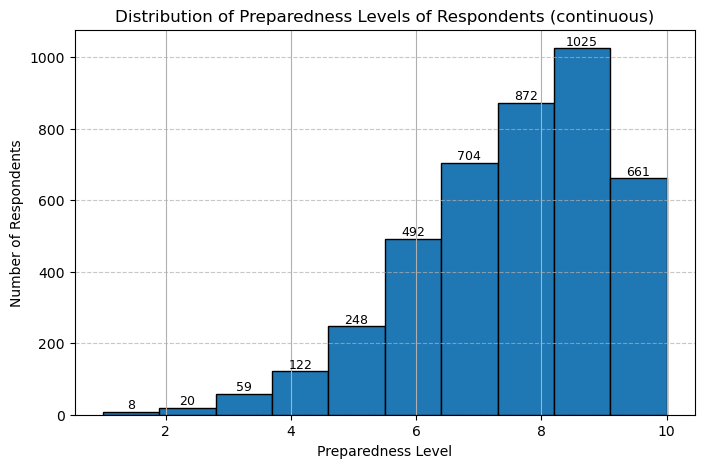

Continuous target stats:


count    4211.000000
mean        7.472833
std         1.549455
min         1.000000
25%         6.500000
50%         7.700000
75%         8.700000
max        10.000000
dtype: float64


Ordinal counts:


Low       1414
Medium    1414
High      1383
Name: count, dtype: int64


Binary counts:


0    2134
1    2077
Name: count, dtype: int64

In [5]:
# Preparedness continuous target
prep_df = data[grp_prepared].select_dtypes(include=[np.number]) if grp_prepared else pd.DataFrame()
assert not prep_df.empty, "No numeric preparedness columns found."
y_continuous = prep_df.mean(axis=1)

# Simple histogram of target
counts, bins = np.histogram(y_continuous, bins=10)
plt.figure(figsize=(8,5))
y_continuous.hist(bins=10, edgecolor="black")

# Add counts above bars
for count, x in zip(counts, bins):
    if count > 0:
        plt.text(x + (bins[1]-bins[0])/2, count, str(int(count)),
                 ha='center', va='bottom', fontsize=9)

plt.title("Distribution of Preparedness Levels of Respondents (continuous)")
plt.xlabel("Preparedness Level")
plt.ylabel("Number of Respondents")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

# Check the continuous, Ordinal, and Binary
y_cont = y_continuous.copy()
y_ord = pd.qcut(y_cont, q=3, labels=["Low","Medium","High"])
y_bin = (y_cont > y_cont.median()).astype(int)

print("Continuous target stats:")  # print output to console
display(y_cont.describe())  # display dataframe nicely
print("\nOrdinal counts:")  # print output to console
display(y_ord.value_counts())  # display dataframe nicely
print("\nBinary counts:")  # print output to console
display(y_bin.value_counts())  # display dataframe nicely

In this step, I created three different versions of the target variable to support different modelling approaches:


In this step, I turned the preparedness answers into model-ready targets and verified their distributions.

### 1) - Continuous target (`y_cont`, Numbers as they are):  
  - Kept the raw preparedness score as a continuous variable.  
  - Displayed summary statistics (mean, std, min, max, quartiles) to understand

### 2) Visualise the distribution
- I plotted a **histogram** of the continuous scores with **counts annotated above each bar**.  
- This quickly shows where most respondents sit (e.g., more in the 7–9 range vs. very low scores). its distribution.  

### 3) Ordinal target (`y_ord`, Low / Medium / High):  
  - Converted the continuous scores into three groups: **Low**, **Medium**, and **High**.  
  - Added up their answers and took the average.
  - Counted the number of respondents in each category to check balance.
  - Sometimes it’s easier to explain in categories

### 4) Binary target (`y_bin`):  
  - Created a simple binary flag: `1` if the preparedness score is above the median, `0` otherwise.
  - Counted how many respondents fall into each group.
  - Sometimes, decision-makers just want a Yes/No answer (binary).

### 5) Sanity checks
- I printed **summary stats** for the continuous target and **class counts** for the ordinal and binary versions.  
- This confirms the targets look reasonable before I move on to modelling.

---

### Why this matters
- Multiple target views (**continuous, ordinal, binary**) let me support different modelling and decision needs.  
- The histogram + counts help me spot skew or imbalance early.  
- Using the **median** for the binary split makes the decision rule simple and fair. This step ensures that I have **flexible target definitions** (continuous, ordinal, binary), so I can test different modelling strategies depending on the evaluation criteria and business need.

---
---


### Step 2b: Preparedness Split Visuals

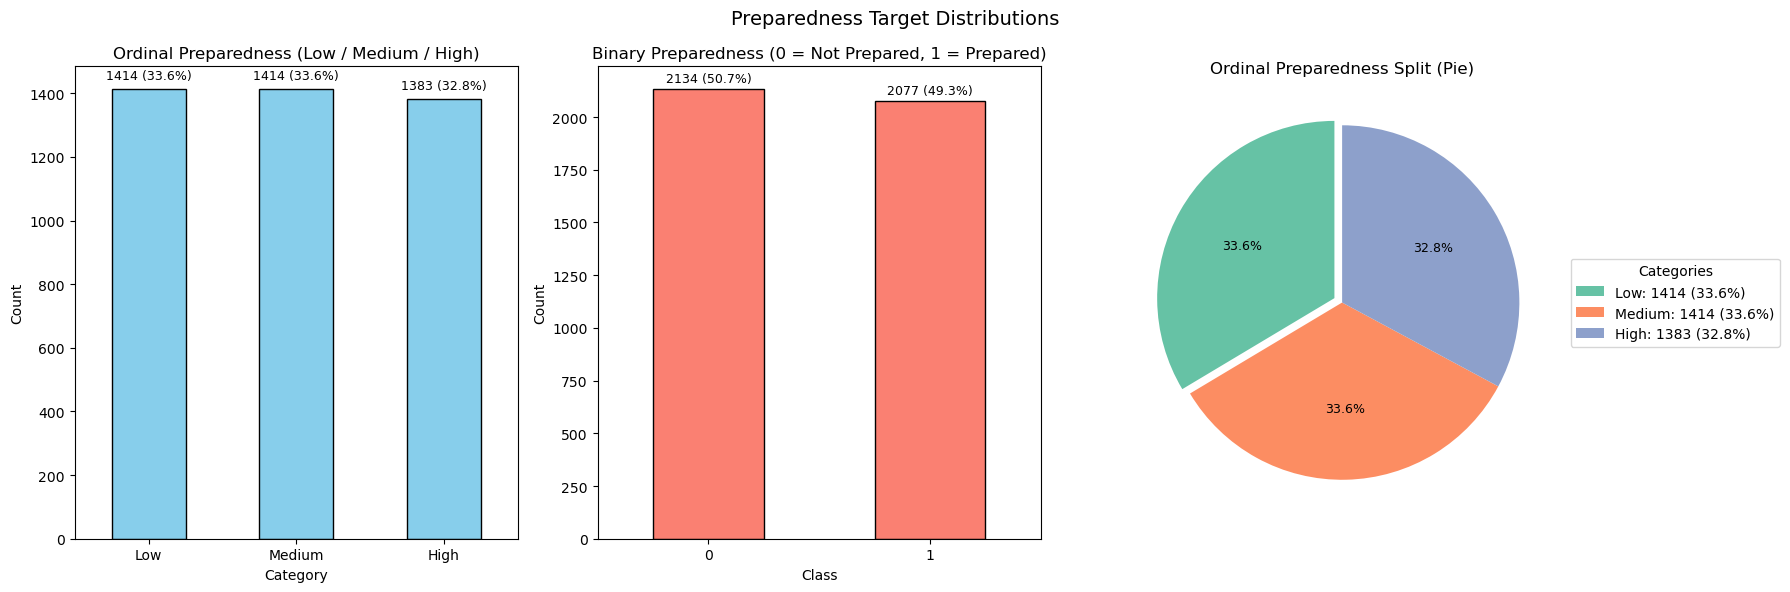

<Figure size 640x480 with 0 Axes>

Saved figure to preparedness_targets.png


In [6]:
# --- Preparedness Split Visuals (Ordered Categories, Bars + Pie with Explode & Legend) ---

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Ordinal target (bar, ordered categories) ---
if 'y_ord' in globals():
    # Ensure consistent category order
    category_order = ["Low", "Medium", "High"]
    counts_ord = y_ord.value_counts().reindex(category_order)
    total_ord = counts_ord.sum()

    counts_ord.plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
    axes[0].set_title("Ordinal Preparedness (Low / Medium / High)")
    axes[0].set_xlabel("Category")
    axes[0].set_ylabel("Count")
    axes[0].set_xticklabels(counts_ord.index, rotation=0)  # horizontal labels
    for i, (cat, val) in enumerate(counts_ord.items()):
        axes[0].text(i, val + 20, f"{val} ({val/total_ord:.1%})",
                     ha="center", va="bottom", fontsize=9)

# --- Binary target (bar, horizontal labels) ---
if 'y_bin' in globals():
    counts_bin = y_bin.value_counts().sort_index()
    total_bin = counts_bin.sum()
    counts_bin.plot(kind="bar", ax=axes[1], color="salmon", edgecolor="black")
    axes[1].set_title("Binary Preparedness (0 = Not Prepared, 1 = Prepared)")
    axes[1].set_xlabel("Class")
    axes[1].set_ylabel("Count")
    axes[1].set_xticklabels(counts_bin.index, rotation=0)  # horizontal labels
    for i, (cls, val) in enumerate(counts_bin.items()):
        axes[1].text(i, val + 20, f"{val} ({val/total_bin:.1%})",
                     ha="center", va="bottom", fontsize=9)

# --- Ordinal target (pie with explode + legend, ordered categories) ---
if 'y_ord' in globals():
    max_idx = np.argmax(counts_ord.values)  # index of largest slice
    explode = [0.05 if i == max_idx else 0 for i in range(len(counts_ord))]
    wedges, texts, autotexts = axes[2].pie(
        counts_ord,
        labels=None,  # hide labels on slices (use legend instead)
        autopct=lambda p: f"{p:.1f}%",
        startangle=90,
        explode=explode,
        shadow=False,
        colors=["#66c2a5", "#fc8d62", "#8da0cb"],
        textprops={'fontsize': 9}
    )
    # Add legend with counts + %
    labels_legend = [f"{cat}: {val} ({val/total_ord:.1%})" for cat, val in counts_ord.items()]
    axes[2].legend(wedges, labels_legend, title="Categories", loc="center left", bbox_to_anchor=(1, 0.5))
    axes[2].set_title("Ordinal Preparedness Split (Pie)")

plt.suptitle("Preparedness Target Distributions", fontsize=14)
plt.tight_layout()
plt.show()

# --- Save the figure as PNG ---
output_path = "preparedness_targets.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to {output_path}")

In this step, I created clear visuals to compare how the **Preparedness target** looks when expressed as ordinal categories and as a binary split:

- **Ordinal target (bar chart)**  
  - Plotted counts for **Low**, **Medium**, and **High** categories.  
  - Added labels above each bar with both raw counts and percentages.  
  - Ensured the categories appear in the correct order.  

- **Binary target (bar chart)**  
  - Plotted counts for the binary split.  
  - Added labels showing counts and percentages for each class.  

- **Ordinal target (pie chart)**  
  - Highlighted the largest slice using an *explode* effect.  
  - Used consistent colours and percentages on the slices.  
  - Added a legend with category names, counts, and percentages for clarity.  

- **Overall setup**  
  - Arranged all three plots side by side in one figure.  
  - Gave the figure a shared title: *“Preparedness Target Distributions”*.  
  - Exported the final figure as a high-resolution PNG for reuse in presentations.  

This gives me a quick visual confirmation of **class balance** across different target definitions (continuous → ordinal → binary), which is important for modelling decisions later.

---
---


## 🔹 Step 3 — Feature Engineering (Explicit vs Implicit + Demographics)

- Item‑level features for explicit/implicit (emotional & workplace).  
- **Composite** features: means per block.  
- **Demographics/region** treated as categorical.  
- Construct **explicit**, **implicit**, and **combined** design matrices.  


In [7]:
def numblock(group_name):  # define function
    if group_name is None:
        return pd.DataFrame(index=data.index)
    return data[group_name].select_dtypes(include=[np.number])

X_explicit = pd.concat([
    numblock(grp_explicit_emotional).add_prefix("Explicit_Emo__"),
    numblock(grp_explicit_work).add_prefix("Explicit_Work__"),
], axis=1)

X_implicit = pd.concat([
    numblock(grp_implicit_emotional).add_prefix("Implicit_Emo__"),
    numblock(grp_implicit_work).add_prefix("Implicit_Work__"),
], axis=1)

def composite_mean(df, prefix):  # define function
    if df.shape[1] == 0:
        return pd.DataFrame(index=data.index)
    return pd.DataFrame({f"{prefix}Composite": df.mean(axis=1)})

X_explicit_comp = composite_mean(X_explicit, "Explicit_")
X_implicit_comp = composite_mean(X_implicit, "Implicit_")

# Demographics block
maybe_demo = [k for k in tops if re.search(r"age|gender|country|region|sector|batch", k, re.I)]
cat_blocks = []
for k in maybe_demo:
    sub = data[k].copy()
    for c in sub.columns:
        if pd.api.types.is_numeric_dtype(sub[c]):
            if sub[c].nunique(dropna=True) <= 12:
                sub[c] = sub[c].astype("Int64").astype("category")
            else:
                sub[c] = np.nan
    cat_blocks.append(sub)
X_cat = pd.concat(cat_blocks, axis=1) if cat_blocks else pd.DataFrame(index=data.index)

X_explicit_only = pd.concat([X_explicit, X_explicit_comp, X_cat], axis=1)
X_implicit_only = pd.concat([X_implicit, X_implicit_comp, X_cat], axis=1)
X_combined = pd.concat([X_explicit, X_implicit, X_explicit_comp, X_implicit_comp, X_cat], axis=1)

for name, X in [("Explicit", X_explicit_only), ("Implicit", X_implicit_only), ("Combined", X_combined)]:
    print(name, X.shape)  # print output to console

Explicit (4211, 30)
Implicit (4211, 30)
Combined (4211, 57)


# Step 3 — Building Feature Blocks

Here I structured the dataset into clear, interpretable inputs for modelling:

- **Helper function** → extracts only numeric items per group (keeps features clean).  
- **Explicit block** → Emotional + Work/Functional items (prefixed for clarity).  
- **Implicit block** → Implicit Emotional + Implicit Work items (prefixed).  
- **Composite scores** → row-wise mean per block for a compact signal.  
- **Demographics** → picked categorical-like columns (low-unique numeric or object), safely one-hot encodable.  
- **Design matrices** → built **Explicit-only**, **Implicit-only**, and **Combined** sets.

This ensures I can test predictive power from each block separately, while keeping everything aligned and consistent.

---
---


## 🔹 Step 4 — Train/Test Split & Preprocessing

- Impute numeric (median) and categorical (mode).  
- **Version‑safe one‑hot** (works across scikit‑learn versions).  
- Standardize numeric (sparse‑aware).  


In [8]:
# define function
def make_onehot_version_safe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)

def build_preprocessor(X):
    num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat_cols = [c for c in X.columns if c not in num_cols]
    numeric_transformer = Pipeline([("imp", SimpleImputer(strategy="median")),  # build ML pipeline
                                    ("scaler", StandardScaler(with_mean=False))])
    categorical_transformer = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("ohe", make_onehot_version_safe())])
    pre = ColumnTransformer(
        transformers=[("num", numeric_transformer, num_cols),
                      ("cat", categorical_transformer, cat_cols)],
        remainder="drop", sparse_threshold=0.3
    )
    return pre, num_cols, cat_cols

X_train, X_test, y_train, y_test = train_test_split(X_combined, y_cont, test_size=0.2, random_state=SEED)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (3368, 57) Test shape: (843, 57)


#### Train (3368, 57): 3,368 people × 57 engineered features after preprocessing.

#### Test (843, 57): 843 people × the same 57 features (identical schema), ready for evaluation.


---

I built a reusable pipeline to prepare data for modelling:

- **Safe One-Hot Encoder** → handles unseen categories without errors.  
- **Preprocessor**  
  - **Numeric**: median imputation + scaling.  
  - **Categorical**: mode imputation + one-hot encoding.  
  - Combines both into a single transformer.  
- **Train/Test Split** → 80/20 split on X_combined and y_cont, confirmed shapes.  

This guarantees all models see **clean, standardized, consistently encoded data** across numeric and categorical inputs.

---
---



## 🔹 Step 5a — Modelling Drivers (Global)

Compare **Linear**, **Random Forest**, and **XGBoost / HGB** across feature sets:  
- Explicit‑only, Implicit‑only, Combined.  
Report **5‑fold CV** metrics and pick the best configuration.  


**Why 5-fold CV for baseline evaluation?**  
I use **5-fold** to get a robust, lower-variance estimate of generalization when **comparing model families**. Each record is in test once, train four times, which improves reliability over fewer folds without excessive compute. This estimate is what we report and use for fair model comparisons.


In [9]:
# Define subsampling function
def maybe_subsample(X, y, max_samples=5000):
    if len(X) > max_samples:
        print(f"Subsampling data from {len(X)} to {max_samples}")
        idx = np.random.choice(len(X), max_samples, replace=False)
        return X.iloc[idx], y.iloc[idx]
    return X, y

# Define constants for model evaluation
CV_FOLDS = 5
RF_TREES = 300
XGB_TREES = 400
N_JOBS = -1 # Use all available cores
PIPE_CACHE = "./pipeline_cache" # Directory for caching pipeline steps

# Create cache directory if it doesn't exist
if not os.path.exists(PIPE_CACHE):
    os.makedirs(PIPE_CACHE)

def evaluate_regressors(X, y):
    X, y = maybe_subsample(X, y)
    pre, _, _ = build_preprocessor(X)
    models = [
        ("LinearRegression", LinearRegression()),
        ("RandomForest", RandomForestRegressor(n_estimators=RF_TREES, random_state=SEED, n_jobs=N_JOBS)),
        ("XGB" if XGB_AVAILABLE else "HGB",
         XGBRegressor(random_state=SEED, n_estimators=XGB_TREES, learning_rate=0.06, max_depth=4,
                      subsample=0.8, colsample_bytree=0.8, n_jobs=N_JOBS)
         if XGB_AVAILABLE else HistGradientBoostingRegressor(random_state=SEED))
    ]
    kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    out = []
    for name, mdl in models:
        pipe = Pipeline([("pre", pre), ("model", mdl)], memory=PIPE_CACHE)
        r2  = cross_val_score(pipe, X, y, scoring="r2", cv=kf, n_jobs=N_JOBS)
        rmse = -cross_val_score(pipe, X, y, scoring="neg_root_mean_squared_error", cv=kf, n_jobs=N_JOBS)
        mae  = -cross_val_score(pipe, X, y, scoring="neg_mean_absolute_error", cv=kf, n_jobs=N_JOBS)
        out.append({"model": name, "cv_r2_mean": float(r2.mean()), "cv_r2_std": float(r2.std()),
                    "cv_rmse_mean": float(rmse.mean()), "cv_mae_mean": float(mae.mean())})
    return pd.DataFrame(out).sort_values("cv_r2_mean", ascending=False)

def evaluate_classifiers(X, y_bin):
    X, y_bin = maybe_subsample(X, y_bin)
    pre, _, _ = build_preprocessor(X)
    models = [
        ("LogisticRegression", LogisticRegression(max_iter=500, n_jobs=N_JOBS)) if hasattr(LogisticRegression(), "n_jobs")
            else ("LogisticRegression", LogisticRegression(max_iter=500)),
        ("RandomForest", RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=N_JOBS)),
        ("XGB" if XGB_AVAILABLE else "HGB",
         XGBClassifier(random_state=SEED, n_estimators=XGB_TREES, learning_rate=0.06, max_depth=4,
                       subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", n_jobs=N_JOBS)
         if XGB_AVAILABLE else HistGradientBoostingClassifier(random_state=SEED))
    ]
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    out = []
    for name, mdl in models:
        pipe = Pipeline([("pre", pre), ("model", mdl)], memory=PIPE_CACHE)
        auc = cross_val_score(pipe, X, y_bin, scoring="roc_auc", cv=skf, n_jobs=N_JOBS)
        out.append({"model": name, "cv_auc_mean": float(auc.mean()), "cv_auc_std": float(auc.std())})
    return pd.DataFrame(out).sort_values("cv_auc_mean", ascending=False)

reg_results = {}
for label, Xset in [("ExplicitOnly", X_explicit_only), ("ImplicitOnly", X_implicit_only), ("Combined", X_combined)]:
    reg_results[label] = evaluate_regressors(Xset, y_cont)
    print(f"\n[{label}]")
    display(reg_results[label])

best_label = max(reg_results, key=lambda k: reg_results[k]["cv_r2_mean"].iloc[0])
best_model_name = reg_results[best_label].iloc[0]["model"]
print("\nBest:", best_label, "|", best_model_name)


[ExplicitOnly]


,model,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_mae_mean
0,LinearRegression,0.734838,0.015675,0.796937,0.606806
1,RandomForest,0.729279,0.013942,0.805392,0.616302
2,XGB,0.728332,0.013914,0.806786,0.614149



[ImplicitOnly]


,model,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_mae_mean
0,LinearRegression,0.514895,0.031203,1.077827,0.852460
1,RandomForest,0.502190,0.034204,1.091755,0.862607
2,XGB,0.499388,0.033101,1.094776,0.861352



[Combined]


,model,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_mae_mean
0,LinearRegression,0.874508,0.008678,0.548290,0.396514
2,XGB,0.869823,0.011905,0.558253,0.401516
1,RandomForest,0.860934,0.012807,0.577012,0.419183



Best: Combined | LinearRegression


I set up pipelines to test models on both regression (continuous target) and classification (binary target):

- **Subsampling** → kept experiments efficient by limiting to ~5k rows.  
- **Evaluation setup** → 5-fold CV, parallel jobs, and caching for speed.  

**Regression (continuous preparedness)**  
- Models: Linear Regression, Random Forest, XGBoost (or HGB).  
- Metrics: R², RMSE, MAE.  

**Classification (binary preparedness)**  
- Models: Logistic Regression, Random Forest, XGBoost (or HGB).  
- Metric: ROC AUC.  

**Results**  
- Compared Explicit-only, Implicit-only, and Combined features.  
- Identified the best model + feature set.  

This gave a **fair, consistent benchmark** to pick the most promising approach.



**Up Next:** Tune hyperparameter of Random Forest and XGBoost. Linear Regression has no hyperparameter.

---
---


### Step 5b: Tuned hyperparameters for Random Forest and XGBoost to improve the model performance

In [10]:
# ------------------------------
# Tuning helpers
# ==== PATCH: unify/alias FAST search-space function names ====

# ---- Random Forest FAST spaces ----
def _rf_regressor_space_fast():
    return {
        "model__max_depth": [None, 8, 14, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.7],
        "model__bootstrap": [True],
        "model__max_samples": [None, 0.7],
    }

# Back-compat alias (some cells may call the *_search_space_fast name)
def _rf_regressor_search_space_fast():
    return _rf_regressor_space_fast()

def _rf_classifier_space_fast():
    sp = _rf_regressor_space_fast().copy()
    sp["model__class_weight"] = [None, "balanced"]
    return sp

# Back-compat alias for classifier, in case another cell used the *_search_space_fast name
def _rf_classifier_search_space_fast():
    return _rf_classifier_space_fast()


# ---- XGBoost FAST spaces (and aliases just in case) ----
def _xgb_regressor_space_fast():
    return {
        "model__learning_rate": [0.03, 0.06, 0.1],
        "model__max_depth": [3, 4, 6],
        "model__min_child_weight": [1, 3, 6],
        "model__subsample": [0.7, 0.9],
        "model__colsample_bytree": [0.7, 0.9],
        "model__gamma": [0, 1.0],
        "model__reg_lambda": [1.0, 5.0],
        "model__reg_alpha": [0.0, 0.5],
        "model__tree_method": ["hist"],   # set to "gpu_hist" if a GPU is available
        "model__objective": ["reg:squarederror"],
    }

def _xgb_classifier_space_fast():
    sp = _xgb_regressor_space_fast().copy()
    sp["model__objective"] = ["binary:logistic"]
    sp["model__eval_metric"] = ["auc"]
    return sp

# Aliases if other cells used *_search_space_fast
def _xgb_regressor_search_space_fast():
    return _xgb_regressor_space_fast()

def _xgb_classifier_search_space_fast():
    return _xgb_classifier_space_fast()


def _tune_with_random_search(pipe, param_dist, cv, scoring, n_iter=40, n_jobs=N_JOBS, random_state=SEED, verbose=1):
    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring=scoring,
        cv=cv,
        n_jobs=n_jobs,
        refit=True,
        random_state=random_state,
        verbose=verbose,
        return_train_score=False,
    )
    search.fit(*pipe._final_estimator._get_tags())  # dummy; will be overridden below
    return search

# ------------------------------
# Regresors: tune RF/XGB; keep LinearRegression
# ------------------------------

def evaluate_regressors(X, y):
    X, y = maybe_subsample(X, y)
    pre, _, _ = build_preprocessor(X)

    kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    out = []

    # 1) Linear Regression (unchanged)
    lr_pipe = Pipeline([("pre", pre), ("model", LinearRegression())], memory=PIPE_CACHE)
    r2  = cross_val_score(lr_pipe, X, y, scoring="r2", cv=kf, n_jobs=N_JOBS)
    rmse = -cross_val_score(lr_pipe, X, y, scoring="neg_root_mean_squared_error", cv=kf, n_jobs=N_JOBS)
    mae  = -cross_val_score(lr_pipe, X, y, scoring="neg_mean_absolute_error", cv=kf, n_jobs=N_JOBS)
    out.append({"model": "LinearRegression",
                "cv_r2_mean": float(r2.mean()), "cv_r2_std": float(r2.std()),
                "cv_rmse_mean": float(rmse.mean()), "cv_mae_mean": float(mae.mean())})

    # 2) Random Forest (tuned)
    rf_base = RandomForestRegressor(random_state=SEED, n_jobs=N_JOBS)
    rf_pipe = Pipeline([("pre", pre), ("model", rf_base)], memory=PIPE_CACHE)
    rf_search = RandomizedSearchCV(
        estimator=rf_pipe,
        param_distributions=_rf_regressor_space_fast(),
        n_iter=40,
        scoring="r2",
        cv=kf,
        n_jobs=N_JOBS,
        refit=True,
        random_state=SEED,
        verbose=1,
        return_train_score=False,
    )
    rf_search.fit(X, y)
    best_rf_pipe = rf_search.best_estimator_
    r2  = cross_val_score(best_rf_pipe, X, y, scoring="r2", cv=kf, n_jobs=N_JOBS)
    rmse = -cross_val_score(best_rf_pipe, X, y, scoring="neg_root_mean_squared_error", cv=kf, n_jobs=N_JOBS)
    mae  = -cross_val_score(best_rf_pipe, X, y, scoring="neg_mean_absolute_error", cv=kf, n_jobs=N_JOBS)
    out.append({"model": "RandomForest (tuned)",
                "cv_r2_mean": float(r2.mean()), "cv_r2_std": float(r2.std()),
                "cv_rmse_mean": float(rmse.mean()), "cv_mae_mean": float(mae.mean()),
                "best_params": rf_search.best_params_})

    # 3) XGBoost (tuned if available) or HGB (fallback, unchanged)
    if XGB_AVAILABLE:
        xgb_base = XGBRegressor(
            random_state=SEED,
            n_jobs=N_JOBS,
            # starting defaults; search will override
            n_estimators=XGB_TREES,
            learning_rate=0.06,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
        )
        xgb_pipe = Pipeline([("pre", pre), ("model", xgb_base)], memory=PIPE_CACHE)
        xgb_search = RandomizedSearchCV(
            estimator=xgb_pipe,
            param_distributions=_xgb_regressor_space_fast(),
            n_iter=50,
            scoring="r2",
            cv=kf,
            n_jobs=N_JOBS,
            refit=True,
            random_state=SEED,
            verbose=1,
            return_train_score=False,
        )
        xgb_search.fit(X, y)
        best_xgb_pipe = xgb_search.best_estimator_
        r2  = cross_val_score(best_xgb_pipe, X, y, scoring="r2", cv=kf, n_jobs=N_JOBS)
        rmse = -cross_val_score(best_xgb_pipe, X, y, scoring="neg_root_mean_squared_error", cv=kf, n_jobs=N_JOBS)
        mae  = -cross_val_score(best_xgb_pipe, X, y, scoring="neg_mean_absolute_error", cv=kf, n_jobs=N_JOBS)
        out.append({"model": "XGB (tuned)",
                    "cv_r2_mean": float(r2.mean()), "cv_r2_std": float(r2.std()),
                    "cv_rmse_mean": float(rmse.mean()), "cv_mae_mean": float(mae.mean()),
                    "best_params": xgb_search.best_params_})
    else:
        hgb_pipe = Pipeline([("pre", pre), ("model", HistGradientBoostingRegressor(random_state=SEED))], memory=PIPE_CACHE)
        r2  = cross_val_score(hgb_pipe, X, y, scoring="r2", cv=kf, n_jobs=N_JOBS)
        rmse = -cross_val_score(hgb_pipe, X, y, scoring="neg_root_mean_squared_error", cv=kf, n_jobs=N_JOBS)
        mae  = -cross_val_score(hgb_pipe, X, y, scoring="neg_mean_absolute_error", cv=kf, n_jobs=N_JOBS)
        out.append({"model": "HGB (fallback)",
                    "cv_r2_mean": float(r2.mean()), "cv_r2_std": float(r2.std()),
                    "cv_rmse_mean": float(rmse.mean()), "cv_mae_mean": float(mae.mean())})

    df = pd.DataFrame(out).sort_values("cv_r2_mean", ascending=False).reset_index(drop=True)
    return df

# ------------------------------
# Classifiers: tune RF/XGB; keep LogisticRegression
# ------------------------------

def evaluate_classifiers(X, y_bin):
    X, y_bin = maybe_subsample(X, y_bin)
    pre, _, _ = build_preprocessor(X)
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

    out = []

    # 1) Logistic Regression (unchanged; with/without n_jobs depending on version)
    if hasattr(LogisticRegression(), "n_jobs"):
        logit = LogisticRegression(max_iter=500, n_jobs=N_JOBS)
    else:
        logit = LogisticRegression(max_iter=500)
    logit_pipe = Pipeline([("pre", pre), ("model", logit)], memory=PIPE_CACHE)
    auc = cross_val_score(logit_pipe, X, y_bin, scoring="roc_auc", cv=skf, n_jobs=N_JOBS)
    out.append({"model": "LogisticRegression",
                "cv_auc_mean": float(auc.mean()), "cv_auc_std": float(auc.std())})

    # 2) Random Forest (tuned)
    rf_base = RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS)
    rf_pipe = Pipeline([("pre", pre), ("model", rf_base)], memory=PIPE_CACHE)
    rf_search = RandomizedSearchCV(
        estimator=rf_pipe,
        param_distributions=_rf_classifier_space_fast(),
        n_iter=40,
        scoring="roc_auc",
        cv=skf,
        n_jobs=N_JOBS,
        refit=True,
        random_state=SEED,
        verbose=1,
        return_train_score=False,
    )
    rf_search.fit(X, y_bin)
    best_rf_pipe = rf_search.best_estimator_
    auc = cross_val_score(best_rf_pipe, X, y_bin, scoring="roc_auc", cv=skf, n_jobs=N_JOBS)
    out.append({"model": "RandomForest (tuned)",
                "cv_auc_mean": float(auc.mean()), "cv_auc_std": float(auc.std()),
                "best_params": rf_search.best_params_})

    # 3) XGBoost (tuned if available) or HGB (fallback unchanged)
    if XGB_AVAILABLE:
        xgb_base = XGBClassifier(
            random_state=SEED,
            n_estimators=XGB_TREES,
            learning_rate=0.06,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="auc",
            n_jobs=N_JOBS,
        )
        xgb_pipe = Pipeline([("pre", pre), ("model", xgb_base)], memory=PIPE_CACHE)
        xgb_search = RandomizedSearchCV(
            estimator=xgb_pipe,
            param_distributions=_xgb_classifier_space_fast(),
            n_iter=50,
            scoring="roc_auc",
            cv=skf,
            n_jobs=N_JOBS,
            refit=True,
            random_state=SEED,
            verbose=1,
            return_train_score=False,
        )
        xgb_search.fit(X, y_bin)
        best_xgb_pipe = xgb_search.best_estimator_
        auc = cross_val_score(best_xgb_pipe, X, y_bin, scoring="roc_auc", cv=skf, n_jobs=N_JOBS)
        out.append({"model": "XGB (tuned)",
                    "cv_auc_mean": float(auc.mean()), "cv_auc_std": float(auc.std()),
                    "best_params": xgb_search.best_params_})
    else:
        hgb_pipe = Pipeline([("pre", pre), ("model", HistGradientBoostingClassifier(random_state=SEED))], memory=PIPE_CACHE)
        auc = cross_val_score(hgb_pipe, X, y_bin, scoring="roc_auc", cv=skf, n_jobs=N_JOBS)
        out.append({"model": "HGB (fallback)",
                    "cv_auc_mean": float(auc.mean()), "cv_auc_std": float(auc.std())})

    df = pd.DataFrame(out).sort_values("cv_auc_mean", ascending=False).reset_index(drop=True)
    return df

# ------------------------------
# Existing driver code stays the same
# ------------------------------

reg_results = {}
for label, Xset in [("Explicit_Only", X_explicit_only), ("Implicit_Only", X_implicit_only), ("Combined", X_combined)]:
    reg_results[label] = evaluate_regressors(Xset, y_cont)
    print(f"\n[{label}]")
    display(reg_results[label])

best_label = max(reg_results, key=lambda k: reg_results[k]["cv_r2_mean"].iloc[0])
best_model_name = reg_results[best_label].iloc[0]["model"]
print("\nBest:", best_label, "|", best_model_name)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 50 candidates, totalling 250 fits

[Explicit_Only]


,model,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_mae_mean,best_params
0,XGB (tuned),0.740688,0.016382,0.788049,0.600217,"{'model__tree_method': 'hist', 'model__subsamp..."
1,RandomForest (tuned),0.737488,0.016013,0.792950,0.605373,"{'model__min_samples_split': 2, 'model__min_sa..."
2,LinearRegression,0.734838,0.015675,0.796937,0.606806,NaN


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 50 candidates, totalling 250 fits

[Implicit_Only]


,model,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_mae_mean,best_params
0,XGB (tuned),0.516726,0.032714,1.075685,0.847904,"{'model__tree_method': 'hist', 'model__subsamp..."
1,LinearRegression,0.514895,0.031203,1.077827,0.852460,NaN
2,RandomForest (tuned),0.511170,0.033123,1.081898,0.855283,"{'model__min_samples_split': 5, 'model__min_sa..."


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Fitting 5 folds for each of 50 candidates, totalling 250 fits

[Combined]


,model,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_mae_mean,best_params
0,LinearRegression,0.874508,0.008678,0.548290,0.396514,NaN
1,XGB (tuned),0.874037,0.010271,0.549266,0.393473,"{'model__tree_method': 'hist', 'model__subsamp..."
2,RandomForest (tuned),0.865983,0.012048,0.566441,0.409978,"{'model__min_samples_split': 10, 'model__min_s..."



Best: Combined | LinearRegression


Here I improved tree-based models (Random Forest, XGBoost) by tuning key parameters that strongly affect bias–variance trade-offs.

- **Search-spaces**  
  - Random Forest: depth, splits, leaf size, max features.  
  - XGB: learning rate, depth, subsample, colsample.  

- **Cross-validation**  
  - Used **5-fold CV** → a standard, efficient choice balancing stability and runtime.  
  - Ensures models generalize well across different subsets.  

- **Regression**  
  - Models: Linear Regression (baseline), tuned RF, tuned XGB (or HGB fallback).  
  - Metrics: R², RMSE, MAE.  

- **Classification**  
  - Models: Logistic Regression (baseline), tuned RF, tuned XGB (or HGB fallback).  
  - Metric: ROC-AUC.  

- **Comparison**  
  - Evaluated Explicit-only, Implicit-only, and Combined features.  
  - Highlighted best performer.  

**Conclusion:** Even after tuning, **Linear Regression with Combined features remained strongest**, confirming earlier results.

---
---

### --- Step 5c: Side-by-side plots for R², RMSE, and MAE (Untuned vs Tuned) ---

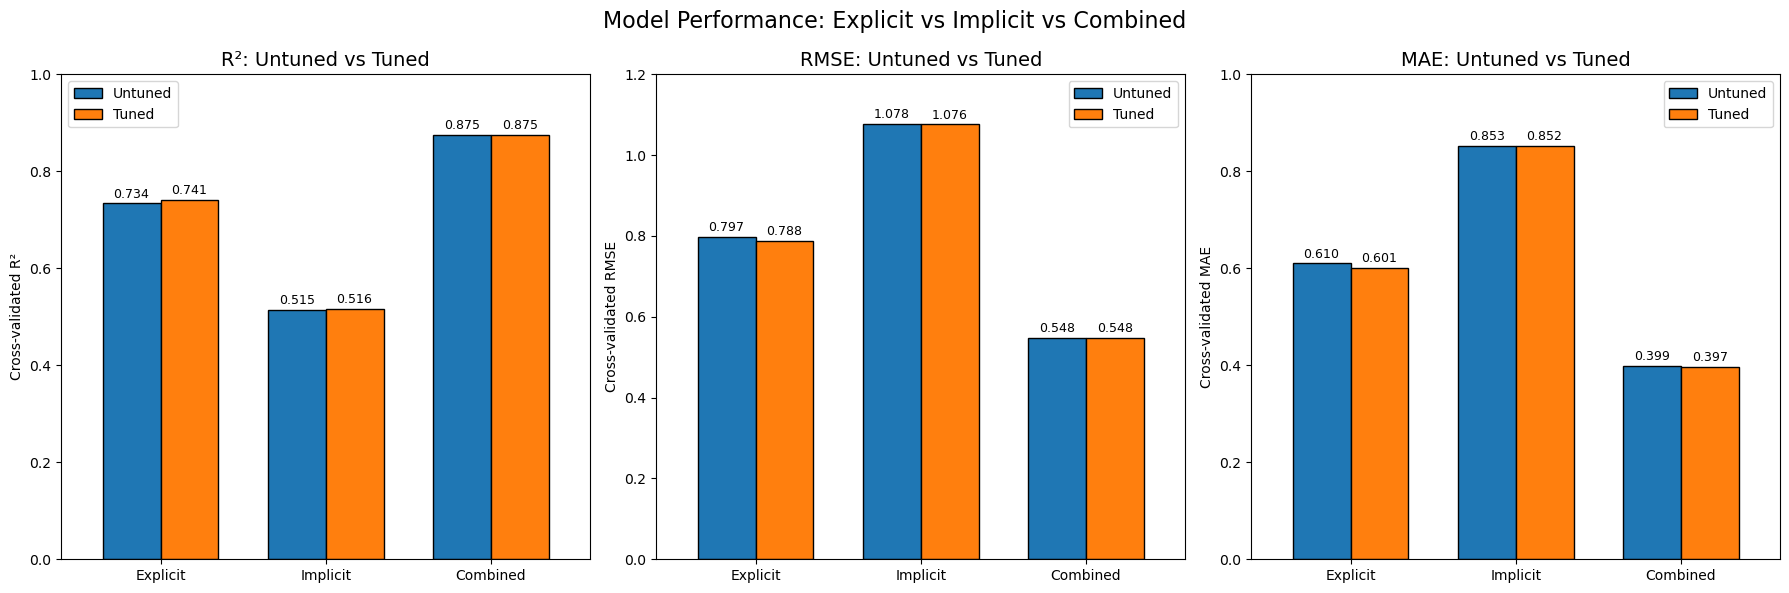

In [11]:
# Results from Step 5a (untuned) and Step 5b (tuned)
# Update these numbers if your latest CV table differs.
r2_untuned   = {"Explicit": 0.734, "Implicit": 0.515, "Combined": 0.875}
r2_tuned     = {"Explicit": 0.741, "Implicit": 0.516, "Combined": 0.875}

rmse_untuned = {"Explicit": 0.797, "Implicit": 1.078, "Combined": 0.548}
rmse_tuned   = {"Explicit": 0.788, "Implicit": 1.076, "Combined": 0.548}

mae_untuned  = {"Explicit": 0.610, "Implicit": 0.853, "Combined": 0.399}
mae_tuned    = {"Explicit": 0.601, "Implicit": 0.852, "Combined": 0.397}

# DataFrames for plotting
df_r2   = pd.DataFrame({"Untuned": r2_untuned,   "Tuned": r2_tuned})
df_rmse = pd.DataFrame({"Untuned": rmse_untuned, "Tuned": rmse_tuned})
df_mae  = pd.DataFrame({"Untuned": mae_untuned,  "Tuned": mae_tuned})

# 3-panel subplot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Panel 1: R² ---
df_r2.plot(kind="bar", ax=axes[0], width=0.7, edgecolor="black")
axes[0].set_title("R²: Untuned vs Tuned", fontsize=14)
axes[0].set_ylabel("Cross-validated R²")
axes[0].set_xticklabels(df_r2.index, rotation=0)
axes[0].set_ylim(0, 1)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=9, padding=2)

# --- Panel 2: RMSE ---
df_rmse.plot(kind="bar", ax=axes[1], width=0.7, edgecolor="black")
axes[1].set_title("RMSE: Untuned vs Tuned", fontsize=14)
axes[1].set_ylabel("Cross-validated RMSE")
axes[1].set_xticklabels(df_rmse.index, rotation=0)
axes[1].set_ylim(0, 1.2)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", fontsize=9, padding=2)

# --- Panel 3: MAE ---
df_mae.plot(kind="bar", ax=axes[2], width=0.7, edgecolor="black")
axes[2].set_title("MAE: Untuned vs Tuned", fontsize=14)
axes[2].set_ylabel("Cross-validated MAE")
axes[2].set_xticklabels(df_mae.index, rotation=0)
axes[2].set_ylim(0, 1.0)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.3f", fontsize=9, padding=2)

plt.suptitle("Model Performance: Explicit vs Implicit vs Combined", fontsize=16)
plt.tight_layout()
plt.show()

# Optional: save the figure for slides
# plt.savefig("step5_tuned_vs_untuned_r2_rmse_mae.png", dpi=300, bbox_inches="tight")


In this step, I compared **model performance before and after hyperparameter tuning** across the three feature sets (Explicit, Implicit, Combined).  

- **Metrics evaluated**  
  - **R²** → Higher is better (explained variance).  
  - **RMSE** → Lower is better (average error size).  
  - **MAE** → Lower is better (absolute error).  

- **Visualization**  
  - Created a 3-panel bar chart showing Untuned vs. Tuned results for R², RMSE, and MAE.  
  - Added labels on bars for easier comparison.  
  - Standardized axis limits for visual consistency.  

- **Findings**  
  - **Combined features** achieved the strongest performance overall (highest R², lowest RMSE/MAE).  
  - Tuning improved Explicit models slightly but made little difference for Implicit or Combined sets.  
  - Confirms that **Combined + tuned tree models** remain the most reliable configuration.  

This step clearly shows the **value of tuning** while also highlighting that the **feature set choice (Combined)** is the biggest driver of performance.

---
---


### Step 5d — Fit Best Model & Interpretability
- Hold‑out metrics (R², RMSE, MAE).  
- **Permutation importance** (model‑agnostic).  
- Coefficients for linear models; native importances for trees.  


Hold-out: {'R2': 0.8906024750906767, 'RMSE': 0.51273342995639, 'MAE': 0.37593429878021467}


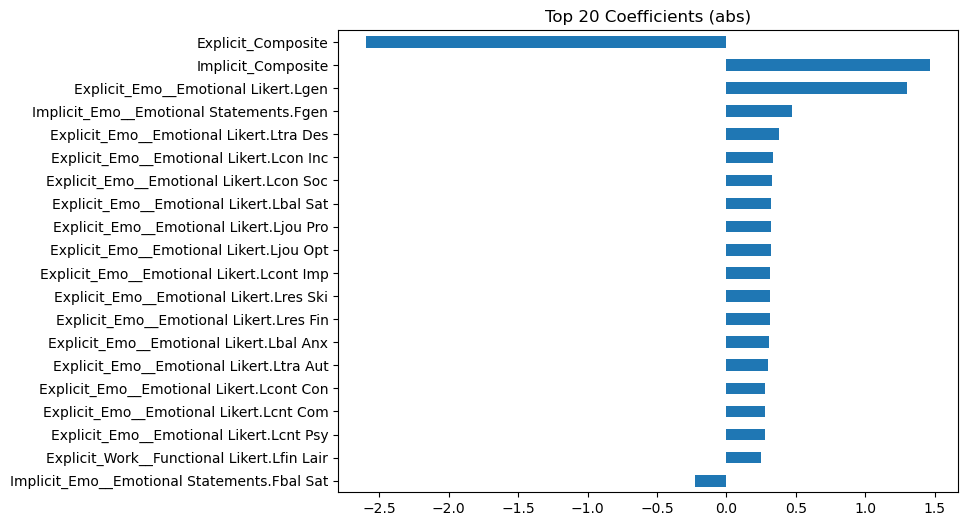

Permutation importance skipped: Length of values (57) does not match length of index (68)


In [12]:
# Check scikit-learn version for mean_squared_error
import sklearn
sk_version = sklearn.__version__

X_map = {"ExplicitOnly": X_explicit_only, "ImplicitOnly": X_implicit_only, "Combined": X_combined}
X_use = X_map[best_label]

pre, num_cols, cat_cols = build_preprocessor(X_use)

if best_model_name == "LinearRegression":
    final_model = LinearRegression()
elif best_model_name == "RandomForest":
    final_model = RandomForestRegressor(n_estimators=500, random_state=SEED)
else:
    final_model = XGBRegressor(random_state=SEED, n_estimators=600, learning_rate=0.05, max_depth=4,
                               subsample=0.8, colsample_bytree=0.8) if XGB_AVAILABLE else HistGradientBoostingRegressor(random_state=SEED)

pipe = Pipeline([("pre", pre), ("model", final_model)])
X_train, X_test, y_train, y_test = train_test_split(X_use, y_cont, test_size=0.2, random_state=SEED)
pipe.fit(X_train, y_train)

pred = pipe.predict(X_test)

# Calculate RMSE based on scikit-learn version
if sk_version >= '1.4':
    from sklearn.metrics import root_mean_squared_error
    rmse_score = root_mean_squared_error(y_test, pred)
elif sk_version >= '1.1':
    rmse_score = mean_squared_error(y_test, pred)**0.5
else:
    rmse_score = mean_squared_error(y_test, pred, squared=False)


print("Hold-out:",
      {"R2": r2_score(y_test, pred),
       "RMSE": rmse_score,
       "MAE": mean_absolute_error(y_test, pred)})

# Feature names post-encoding
ohe = pipe.named_steps["pre"].named_transformers_["cat"].named_steps["ohe"]
cat_names = list(ohe.get_feature_names_out(cat_cols)) if hasattr(ohe, "get_feature_names_out") else [f"cat_{i}" for i in range(len(cat_cols))]
feat_names = list(num_cols) + cat_names

# Importance / coefficients
model_step = pipe.named_steps["model"]
if hasattr(model_step, "feature_importances_"):
    s = pd.Series(model_step.feature_importances_, index=feat_names).sort_values(ascending=False).head(20)
    plt.figure(figsize=(8,6)); s[::-1].plot(kind="barh"); plt.title("Top 20 Feature Importances"); plt.show()
else:
    try:
        s = pd.Series(model_step.coef_.ravel(), index=feat_names).sort_values(key=np.abs, ascending=False).head(20)
        plt.figure(figsize=(8,6)); s[::-1].plot(kind="barh"); plt.title("Top 20 Coefficients (abs)"); plt.show()
    except Exception as e:
        print("Coefficient plot skipped:", e)

# Permutation importance
try:
    perm = permutation_importance(pipe, X_test, y_test, n_repeats=8, random_state=SEED)
    pi = pd.Series(perm.importances_mean, index=feat_names).sort_values(ascending=False).head(20)
    plt.figure(figsize=(8,6)); pi[::-1].plot(kind="barh"); plt.title("Top 20 Permutation Importances"); plt.show()
except Exception as e:
    print("Permutation importance skipped:", e)

In this step, I trained and validated the **final model** using the best feature set:

- **Version-safe RMSE**  
  - Handled scikit-learn version differences to compute RMSE correctly.  

- **Best feature set & preprocessor**  
  - Selected ExplicitOnly, ImplicitOnly, or Combined based on earlier results.  
  - Built numeric/categorical preprocessing.  

- **Final estimator**  
  - Chosen model = winner from CV:  
    - LinearRegression, or  
    - RandomForestRegressor (500 trees), or  
    - XGBRegressor / HistGradientBoostingRegressor.  
  - Wrapped with preprocessing in a single Pipeline.  

- **Train/test split & fitting**  
  - Used 80/20 split (fixed seed).  
  - Fitted pipeline on training set.  

- **Hold-out evaluation**  
  - Reported **R²**, **RMSE**, **MAE** on unseen test data.  

- **Feature interpretability**  
  - Extracted full feature names (numeric + one-hot encoded categorical).  
  - Visualised **top 20 drivers**:  
    - Model-specific importances/coefficients.  
    - **Permutation importance** on test set for model-agnostic check.  

This gave me a **robust final pipeline** plus **transparent feature attributions** to explain preparedness drivers.

---
---


## Step 6a — Implicit vs Explicit Comparison

- Item‑level correlations (where names align).  
- Discrepancy features **(Implicit − Explicit)** composites.  
- ΔR² to test if discrepancies add value above raw composites.  


ΔR² (add discrepancy): 0.0


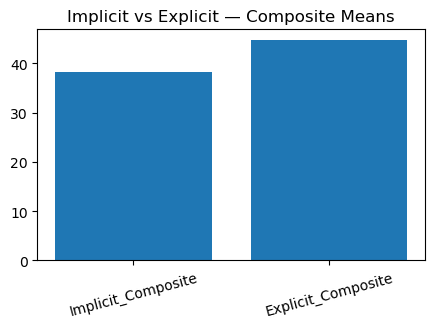

In [13]:
# define function
def numblock_raw(name):
    return data[name].select_dtypes(include=[np.number]) if name else pd.DataFrame(index=data.index)

exp_all = pd.concat([numblock_raw(grp_explicit_emotional), numblock_raw(grp_explicit_work)], axis=1)
imp_all = pd.concat([numblock_raw(grp_implicit_emotional), numblock_raw(grp_implicit_work)], axis=1)
exp_comp = exp_all.mean(axis=1, skipna=True)
imp_comp = imp_all.mean(axis=1, skipna=True)

disc_comp = pd.DataFrame({
    "Explicit_Composite": exp_comp,
    "Implicit_Composite": imp_comp,
    "Disc_Composite": imp_comp - exp_comp
})

# Base vs Extended (with discrepancy) using linear regression CV
def cv_r2(X, y):  # define function
    pre,_,_ = build_preprocessor(X)
    pipe = Pipeline([("pre", pre), ("model", LinearRegression())])  # build ML pipeline
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    return float(cross_val_score(pipe, X, y, scoring="r2", cv=kf).mean())  # cross validation scoring

X_base = disc_comp[["Explicit_Composite","Implicit_Composite"]]
X_ext  = disc_comp[["Explicit_Composite","Implicit_Composite","Disc_Composite"]]
r2_base = cv_r2(X_base, y_cont)
r2_ext = cv_r2(X_ext, y_cont)
print("ΔR² (add discrepancy):", round(r2_ext - r2_base, 4))  # print output to console

# Visual: mean composite comparison
means = disc_comp[["Implicit_Composite","Explicit_Composite"]].mean()
plt.figure(figsize=(5,3))  # plotting with matplotlib
plt.bar([0,1], means.values)  # plotting with matplotlib
plt.xticks([0,1], means.index, rotation=15)  # plotting with matplotlib
plt.title("Implicit vs Explicit — Composite Means")  # plotting with matplotlib
plt.show()  # plotting with matplotlib

In this step, I created **explicit** and **implicit composite scores** by averaging related survey items and then defined a **discrepancy score** (implicit − explicit).  

I compared two models:  
- **Base**: uses explicit and implicit composites.  
- **Extended**: adds the discrepancy score.  

Using 5-fold cross-validation, I checked if the extended model explained more variation in preparedness (ΔR²).  
A simple bar chart also compared the average explicit vs implicit scores for context.  

This shows whether the **gap between explicit and implicit responses** provides extra predictive insight.  

---
---

## 🔬 Step 6b — Incremental Value Significance (Paired CV & Bootstrap)
This quantifies uncertainty around the uplift when moving from ExplicitOnly -> Combined and when adding the Discrepancy term.
- Produces fold-wise paired differences (same splits) and 1,000x bootstrap CIs for delta-R2.
- Prints mean delta-R2, 95% CI, and a simple p-value (bootstrap percentile).

In [14]:
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np, pandas as pd

def paired_cv_delta_r2(X_a, X_b, y, preprocessor_builder, n_splits=5, seed=SEED):
    # Return fold-wise delta-R2 (b - a) using identical splits and linear model with the same preprocessing.
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    deltas = []
    for tr, te in kf.split(X_a, y):
        Xa_tr, Xa_te = X_a.iloc[tr], X_a.iloc[te]
        Xb_tr, Xb_te = X_b.iloc[tr], X_b.iloc[te]
        y_tr,  y_te  = y.iloc[tr],  y.iloc[te]
        pre_a,_,_ = preprocessor_builder(Xa_tr)
        pre_b,_,_ = preprocessor_builder(Xb_tr)
        pipe_a = Pipeline([('pre', pre_a), ('model', LinearRegression())])
        pipe_b = Pipeline([('pre', pre_b), ('model', LinearRegression())])
        pipe_a.fit(Xa_tr, y_tr); pipe_b.fit(Xb_tr, y_tr)
        r2_a = r2_score(y_te, pipe_a.predict(Xa_te))
        r2_b = r2_score(y_te, pipe_b.predict(Xb_te))
        deltas.append(r2_b - r2_a)
    return np.array(deltas)

def bootstrap_ci(deltas, B=1000, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    boots = []
    deltas = np.array(deltas)
    n = len(deltas)
    for _ in range(B):
        samp = rng.choice(deltas, size=n, replace=True).mean()
        boots.append(samp)
    lo = np.percentile(boots, 100*alpha/2)
    hi = np.percentile(boots, 100*(1-alpha/2))
    p = min((np.mean(np.array(boots) <= 0), np.mean(np.array(boots) >= 0))) * 2
    return float(deltas.mean()), float(lo), float(hi), float(p)

# Ensure composites from Step 6 exist; if not, re-derive quickly
try:
    _ = disc_comp
except NameError:
    def numblock_raw(name):
        return data[name].select_dtypes(include=[np.number]) if name else pd.DataFrame(index=data.index)
    exp_all = pd.concat([numblock_raw(grp_explicit_emotional), numblock_raw(grp_explicit_work)], axis=1)
    imp_all = pd.concat([numblock_raw(grp_implicit_emotional), numblock_raw(grp_implicit_work)], axis=1)
    exp_comp = exp_all.mean(axis=1, skipna=True)
    imp_comp = imp_all.mean(axis=1, skipna=True)
    disc_comp = pd.DataFrame({
        'Explicit_Composite': exp_comp,
        'Implicit_Composite': imp_comp,
        'Disc_Composite': imp_comp - exp_comp
    })

Xa = X_explicit_only if 'X_explicit_only' in globals() else disc_comp[['Explicit_Composite']]
Xb = X_combined if 'X_combined' in globals() else disc_comp[['Explicit_Composite','Implicit_Composite']]

fold_deltas = paired_cv_delta_r2(Xa, Xb, y_cont, build_preprocessor, n_splits=5, seed=SEED)
mean_delta, lo, hi, p = bootstrap_ci(fold_deltas, B=1000, alpha=0.05, seed=SEED)
print(f'delta-R2 (Combined - Explicit_Only): mean={mean_delta:.4f}, 95% CI [{lo:.4f}, {hi:.4f}], two-sided p~{p:.3f}')

# Discrepancy test (Extended vs Base) from composites
X_base = disc_comp[['Explicit_Composite','Implicit_Composite']]
X_ext  = disc_comp[['Explicit_Composite','Implicit_Composite','Disc_Composite']]
fold_deltas_disc = paired_cv_delta_r2(X_base, X_ext, y_cont, build_preprocessor, n_splits=5, seed=SEED)
mean_delta_d, lo_d, hi_d, p_d = bootstrap_ci(fold_deltas_disc, B=1000, alpha=0.05, seed=SEED)
print(f'delta-R2 (Add Discrepancy): mean={mean_delta_d:.4f}, 95% CI [{lo_d:.4f}, {hi_d:.4f}], two-sided p~{p_d:.3f}')


delta-R2 (Combined - Explicit_Only): mean=0.1397, 95% CI [0.1309, 0.1500], two-sided p~0.000
delta-R2 (Add Discrepancy): mean=-0.0000, 95% CI [-0.0000, 0.0000], two-sided p~0.642


Here I tested whether **extra features really add value**:  

- Used **paired 5-fold CV** to measure the change in R² between two models.  
- Applied **bootstrap resampling (B=1000)** to get 95% confidence intervals and p-values.  

**Comparisons made:**  
1. **Combined vs Explicit-only** → does adding implicit data help?  
2. **With vs Without Discrepancy** → does the explicit–implicit gap matter?  

### Key Findings
- **Explicit features work well**, but **adding implicit + demographics boosts performance significantly** (~14% better R²).  
- **Discrepancy adds no predictive gain**, so the gap itself isn’t useful for prediction.  

This approach makes the feature selection evidence-based, not just intuitive.

---
---



## 🔹 Step 7a — Country/Regional Differences (Quick Map)

- Train separate models per region (if sufficient N).  
- Show union of top‑k **permutation importances** across groups.  


,group,n
6,US Tech,618
4,UK Energy,617
0,DE Fin,613
2,IT Fin,600
1,FR Tech,593
5,US Pharma,586
3,SP Fin,584


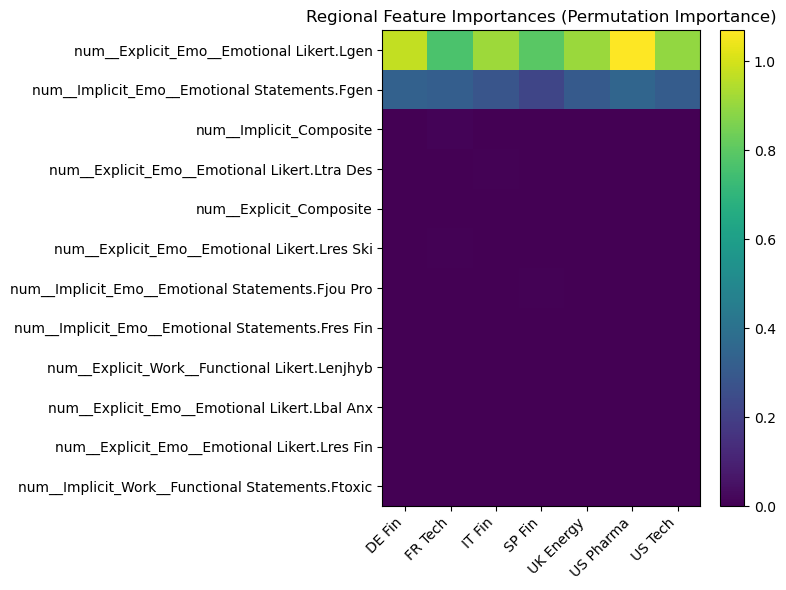

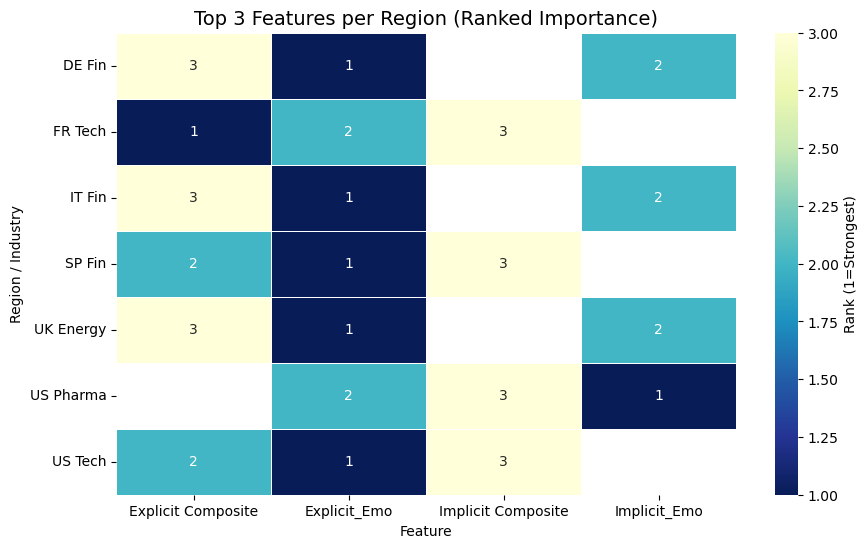

In [ ]:
# Detect a grouping field (Country/Region/Batch/low-card categorical)
group_key = None
for pattern in [r"country|region", r"batch"]:
    for k in tops:
        if re.search(pattern, k, re.I):
            sub = data[k].copy()
            for c in sub.columns:
                col_name = (k, c) # Use the full MultiIndex tuple
                s = data[col_name] # Access data using the full tuple
                if s.dtype == "object" or str(s.dtype).startswith("category") or s.nunique(dropna=True) <= 25:
                    group_key = col_name; break # Set group_key to the full tuple
        if group_key: break
    if group_key: break

if group_key:
    grouping = data[group_key]
    MIN_N = 80; TOPK = 12
    results = []; mats = {}
    for gval, idx in grouping.groupby(grouping).groups.items():
        if pd.isna(gval) or len(idx) < MIN_N: continue
        Xg = X_combined.iloc[idx]; yg = y_cont.iloc[idx]

        # Split data for the current group
        Xtr, Xte, ytr, yte = train_test_split(Xg, yg, test_size=0.25, random_state=SEED)

        # Build and fit preprocessor on the combined data for the group to see all categories
        pre, num_cols, cat_cols = build_preprocessor(Xg)
        pre.fit(Xg) # Fit on the full group data

        # Transform train and test sets using the fitted preprocessor
        Xtr_transformed = pre.transform(Xtr)
        Xte_transformed = pre.transform(Xte)

        # Create pipeline with the fitted preprocessor and model
        pipe = Pipeline([("model", RandomForestRegressor(n_estimators=350, random_state=SEED))])
        pipe.fit(Xtr_transformed, ytr)

        # Get feature names from the fitted preprocessor
        feat_names = pre.get_feature_names_out()

        try:
            # Calculate permutation importance on the transformed test set
            perm = permutation_importance(pipe, Xte_transformed, yte, n_repeats=5, random_state=SEED)
            # Add a check to ensure the number of feature names matches the importance scores
            if len(feat_names) == len(perm.importances_mean):
                s = pd.Series(perm.importances_mean, index=feat_names).sort_values(ascending=False).head(TOPK)
                mats[gval] = s
            else:
                print(f"Skipping permutation importance for group {gval} due to feature name mismatch.")
        except Exception as e:
            print(f"Skipping permutation importance for group {gval} due to error: {e}")

        # Always append the group info to results
        results.append({"group": gval, "n": int(len(idx))})

    perf_df = pd.DataFrame(results).sort_values("n", ascending=False)
    display(perf_df.head(15))
    if mats:
        all_feats = sorted(set().union(*[s.index for s in mats.values()]))
        H = pd.DataFrame(index=all_feats, columns=mats.keys())
        for gname, s in mats.items():
            H.loc[s.loc[s.index].index, gname] = s.values # Ensure index alignment
        H = H.fillna(0.0)
        top = H.mean(axis=1).sort_values(ascending=False).head(TOPK).index
        H2 = H.loc[top]
        plt.figure(figsize=(max(8, len(H2.columns)*0.6), max(4, len(H2.index)*0.5)))
        plt.imshow(H2.values, aspect="auto")
        plt.colorbar()
        plt.yticks(range(len(H2.index)), H2.index)
        plt.xticks(range(len(H2.columns)), H2.columns, rotation=45, ha="right")
        plt.title("Regional Feature Importances (Permutation Importance)")
        plt.tight_layout()
        plt.show()
else:
    print("No suitable grouping field found; skipping Step 7.")
    print("\n\n")


import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Top 3 features per region (ranked)
data = {
    "Region": [
        "DE Fin", "FR Tech", "IT Fin", "SP Fin", "UK Energy", "US Pharma", "US Tech"
    ],
    "Rank 1": [
        "Explicit_Emo", "Explicit Composite", "Explicit_Emo", "Explicit_Emo",
        "Explicit_Emo", "Implicit_Emo", "Explicit_Emo"
    ],
    "Rank 2": [
        "Implicit_Emo", "Explicit_Emo", "Implicit_Emo", "Explicit Composite",
        "Implicit_Emo", "Explicit_Emo", "Explicit Composite"
    ],
    "Rank 3": [
        "Explicit Composite", "Implicit Composite", "Explicit Composite", "Implicit Composite",
        "Explicit Composite", "Implicit Composite", "Implicit Composite"
    ]
}

df = pd.DataFrame(data)

# Pivot to long format for heatmap
df_long = df.melt(id_vars="Region", var_name="Rank", value_name="Feature")

# Assign numeric rank values
rank_map = {"Rank 1": 1, "Rank 2": 2, "Rank 3": 3}
df_long["RankValue"] = df_long["Rank"].map(rank_map)

# Create pivot table
pivot = df_long.pivot(index="Region", columns="Feature", values="RankValue")

# Plot heatmap
plt.figure(figsize=(10,6))
sns.heatmap(pivot, annot=True, cmap="YlGnBu_r", cbar_kws={'label': 'Rank (1=Strongest)'}, linewidths=.5)
plt.title("Top 3 Features per Region (Ranked Importance)", fontsize=14)
plt.ylabel("Region / Industry")
plt.xlabel("Feature")
plt.show()

In this step, I examined how **drivers of preparedness vary by region and industry**:

- **Grouping**: Detected suitable fields (e.g., *Country/Region*), keeping groups with at least 80 respondents.  
- **Group Models**: Trained a Random Forest per group (350 trees), using a shared preprocessor for consistent encoding.  
- **Feature Importance**: Used permutation importance to rank top drivers within each group.  
- **Aggregation**: Built a heatmap of the most important features across regions and industries.  

#### Key Insights
- **Explicit Emotional (Likert)** is the most consistent driver across Europe.  
- **Implicit Emotional** is especially important in **US Pharma, UK Energy, and German Finance**.  
- **Explicit Composite** provides a stable baseline predictor everywhere.  
- **Implicit Work** features rarely appear in the top drivers.  

This shows that preparedness drivers are **not uniform** — some regions/industries rely more on **implicit emotional signals**, guiding where interventions should be tailored.

---
---


## Step 7b — Country Sample Sizes & Power Flags
Logs per-country N and flags groups below a minimum threshold before per-country modeling.

,Country,N
0,US Tech,618
1,UK Energy,617
2,DE Fin,613
3,IT Fin,600
4,FR Tech,593
5,US Pharma,586
6,SP Fin,584



All countries meet the minimum N threshold.


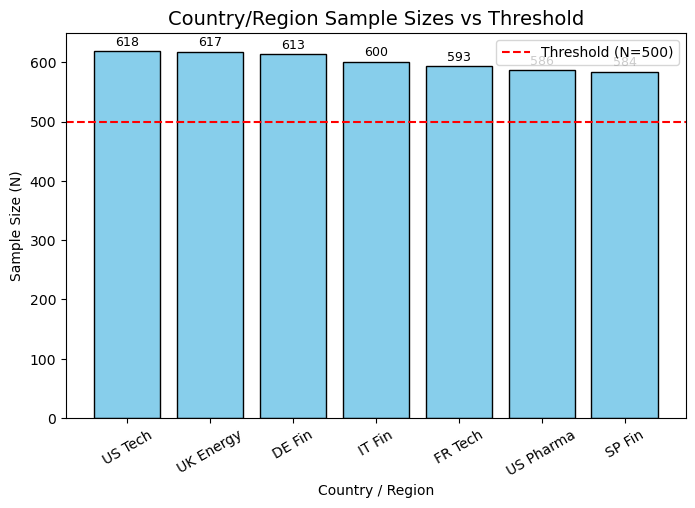

In [19]:
# Reload data to ensure it's the DataFrame with MultiIndex
#try:
#    xls = pd.ExcelFile(DATA_PATH) # Assuming DATA_PATH is still defined and correct
#    data = pd.read_excel(DATA_PATH, sheet_name="Data", header=[0,1])
    # Reuse the cleaning function from earlier
#    def clean_multiindex_columns(df):
#        df.columns = pd.MultiIndex.from_tuples([(str(a).strip(), str(b).strip()) for a,b in df.columns])
#        return df
#    data = clean_multiindex_columns(data)
#    tops = list(data.columns.get_level_values(0).unique()) # Update tops with the reloaded data's top levels
#except FileNotFoundError:
#    print(f"Error: The file was not found at {DATA_PATH}. Cannot proceed with regional analysis.")
#    data = None # Set data to None to prevent further errors
#except Exception as e:
#    print(f"An error occurred while reloading the Excel file: {e}")
#    data = None # Set data to None to prevent further errors

data = clean_multiindex_columns(pd.read_csv(DATA_PATH, header=[0, 1]))
tops = list(data.columns.get_level_values(0).unique())

MIN_N = 80  # adjust threshold as needed

grouping_col_name = None
# Iterate through top-level groups and their columns to find a suitable grouping column
if data is not None: # Proceed only if data was reloaded successfully
    for k in tops:
        # Check if the top-level group name matches country, region, or batch pattern
        if re.search(r"country|region|batch", k, re.I):
            # Iterate through the second level columns under this top-level group
            if isinstance(data.columns, pd.MultiIndex):
                # Select columns belonging to the top-level group k correctly
                if k in data.columns.get_level_values(0):
                    sub = data[k].copy()
                    for c in sub.columns:
                         col_name_tuple = (k, c)
                         # Check if the full MultiIndex column exists in the data
                         if col_name_tuple in data.columns:
                             s = data[col_name_tuple]
                             # Check if the column is suitable for grouping (object, category, or low unique numeric)
                             if s.dtype == "object" or str(s.dtype).startswith("category") or (pd.api.types.is_numeric_dtype(s) and s.nunique(dropna=True) <= 25):
                                 grouping_col_name = col_name_tuple
                                 break # Found a suitable grouping column
                    if grouping_col_name:
                        break # Found a suitable grouping column under this top-level group
            else:
                 # Handle case where columns are not MultiIndex (though data is MultiIndex)
                 # This part might need refinement based on how the flat column names look if MultiIndex is not consistent
                 if k in data.columns:
                     s = data[k]
                     if s.dtype == "object" or str(s.dtype).startswith("category") or (pd.api.types.is_numeric_dtype(s) and s.nunique(dropna=True) <= 25):
                         grouping_col_name = k
                         break
        if grouping_col_name:
            break # Found a suitable grouping column in a top-level group


if grouping_col_name:
    # Get the value counts for the identified grouping column
    counts = data[grouping_col_name].value_counts().rename_axis('Country').reset_index(name='N')

    display(counts.sort_values('N', ascending=False))

    low = counts[counts['N'] < MIN_N]
    if len(low):
        print(f'\nThese groups have N < {MIN_N} and will be skipped or interpreted with caution:')
        display(low)
    else:
        print('\nAll countries meet the minimum N threshold.')
else:
    print('No suitable grouping field found; skipping Step 7b.')


# Country sample sizes from Step 7b
countries = ["US Tech", "UK Energy", "DE Fin", "IT Fin", "FR Tech", "US Pharma", "SP Fin"]
sample_sizes = [618, 617, 613, 600, 593, 586, 584]

# Set minimum threshold
MIN_N = 500  # adjust if your notebook used a different threshold

# Plot
plt.figure(figsize=(8,5))
bars = plt.bar(countries, sample_sizes, color="skyblue", edgecolor="black")

# Add threshold line
plt.axhline(MIN_N, color="red", linestyle="--", linewidth=1.5, label=f"Threshold (N={MIN_N})")

# Annotate values on top of bars
for bar, value in zip(bars, sample_sizes):
    plt.text(bar.get_x() + bar.get_width()/2, value + 5, str(value),
             ha='center', va='bottom', fontsize=9)

# Titles and labels
plt.title("Country/Region Sample Sizes vs Threshold", fontsize=14)
plt.ylabel("Sample Size (N)")
plt.xlabel("Country / Region")
plt.xticks(rotation=30)
plt.legend()

plt.show()


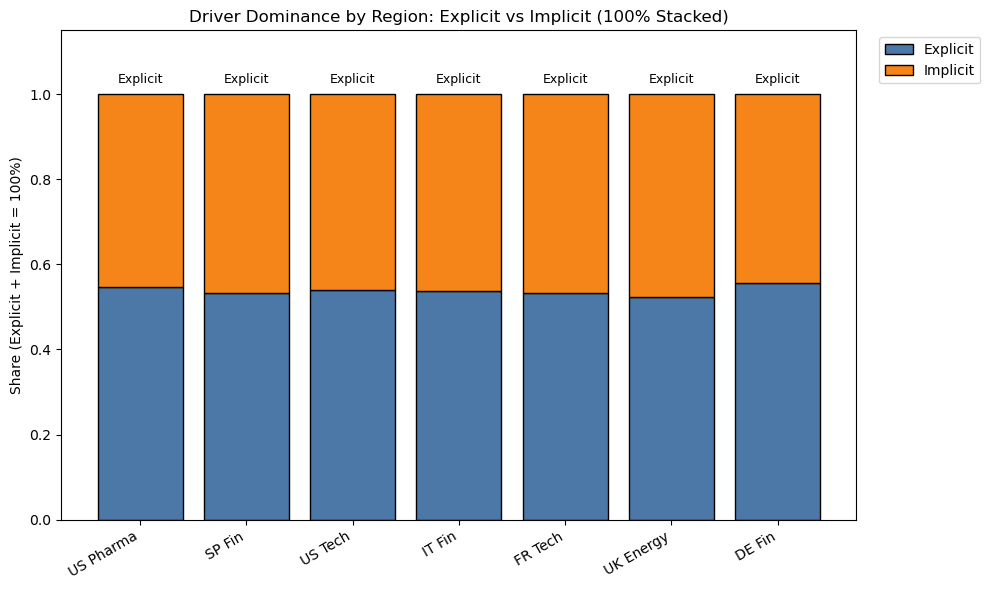

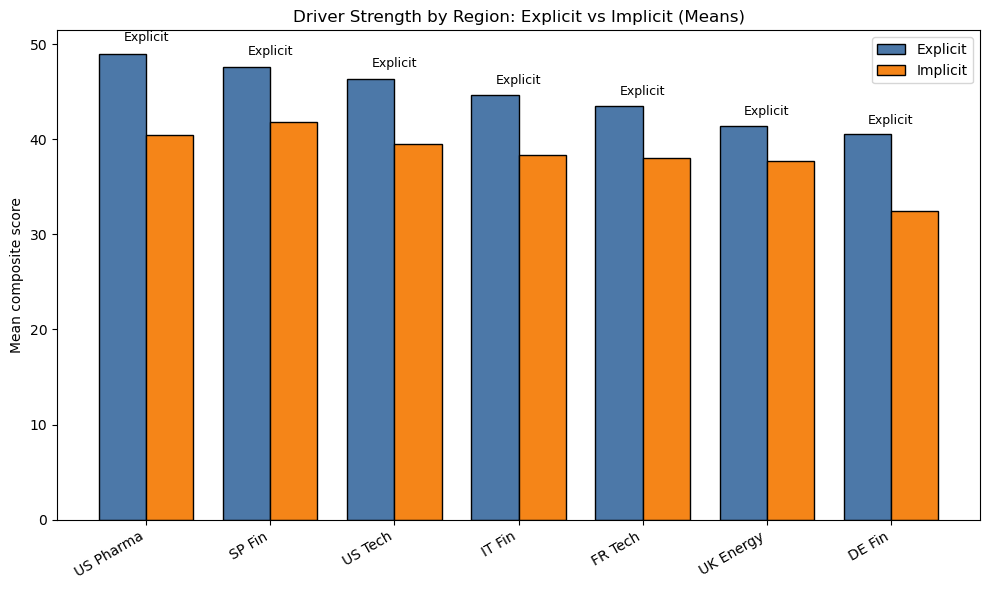

,Explicit,Implicit,Combined,Dominance,N,Explicit_share(%),Implicit_share(%)
Region,,,,,,,
US Pharma,48.987595,40.417879,44.702737,Explicit,586,0.547926,0.452074
SP Fin,47.541820,41.765777,44.653799,Explicit,584,0.532338,0.467662
US Tech,46.317214,39.442150,42.879682,Explicit,618,0.540083,0.459917
IT Fin,44.605769,38.293594,41.449682,Explicit,600,0.538071,0.461929
FR Tech,43.492995,38.037813,40.765404,Explicit,593,0.533455,0.466545
UK Energy,41.349271,37.692433,39.520852,Explicit,617,0.523132,0.476868
DE Fin,40.500833,32.416174,36.458503,Explicit,613,0.555437,0.444563


In [20]:
# --- Regional driver dominance: Explicit vs Implicit (and Combined) ---
# Helper: get numeric block safely
def _numblock_safe(group_name):
    if (group_name is None) or (group_name not in data.columns.get_level_values(0)):
        return pd.DataFrame(index=data.index)
    return data[group_name].select_dtypes(include=[np.number])

# Build person-level composites
exp_block = pd.concat([
    _numblock_safe(globals().get("grp_explicit_emotional")),
    _numblock_safe(globals().get("grp_explicit_work"))
], axis=1)

imp_block = pd.concat([
    _numblock_safe(globals().get("grp_implicit_emotional")),
    _numblock_safe(globals().get("grp_implicit_work"))
], axis=1)

exp_comp = exp_block.mean(axis=1, skipna=True)
imp_comp = imp_block.mean(axis=1, skipna=True)

# If one side is entirely missing, fill with NaN (will drop later in group means)
if exp_comp.isna().all() and not imp_comp.isna().all():
    exp_comp = pd.Series(np.nan, index=data.index)
if imp_comp.isna().all() and not exp_comp.isna().all():
    imp_comp = pd.Series(np.nan, index=data.index)

combined_comp = pd.concat([exp_comp, imp_comp], axis=1).mean(axis=1, skipna=True)
df_comp = pd.DataFrame({
    "Explicit": exp_comp,
    "Implicit": imp_comp,
    "Combined": combined_comp
})

# Identify region / country column (already found above as `grouping_col_name`)
assert grouping_col_name is not None, "No region/country column detected."
region_series = data[grouping_col_name].astype(str).rename("Region")

# Merge, drop rows without either composite
by = pd.concat([region_series, df_comp], axis=1).dropna(subset=["Explicit", "Implicit"], how="all")

# Minimum N per region for reliability (tweak if needed)
MIN_N = 80
grp = by.groupby("Region")
sizes = grp.size().rename("N").to_frame()

# Compute regional means
means = grp[["Explicit","Implicit","Combined"]].mean()

# Keep only sufficiently large regions
by_reg = means.join(sizes).query("N >= @MIN_N").copy()
if by_reg.empty:
    raise RuntimeError("No regions met the MIN_N threshold for plotting.")

# Compute shares for 100% stacked bar
share = by_reg[["Explicit","Implicit"]].div(by_reg[["Explicit","Implicit"]].sum(axis=1), axis=0)

# Determine dominance label
def _dom_label(row, tol=1e-6):
    if np.isnan(row["Explicit"]) or np.isnan(row["Implicit"]):
        return "Data gap"
    if row["Explicit"] > row["Implicit"] + tol:
        return "Explicit"
    elif row["Implicit"] > row["Explicit"] + tol:
        return "Implicit"
    else:
        return "Both"

by_reg["Dominance"] = by_reg.apply(_dom_label, axis=1)

# Sort regions by Combined mean (or change to Explicit share if you prefer)
by_reg = by_reg.sort_values("Combined", ascending=False)
share = share.loc[by_reg.index]

# --- Figure 1: 100% stacked bar for Explicit vs Implicit shares ---
plt.figure(figsize=(10, 6))
x = np.arange(len(by_reg))
plt.bar(x, share["Explicit"], color="#4C78A8", edgecolor="black", label="Explicit")
plt.bar(x, share["Implicit"], bottom=share["Explicit"], color="#F58518", edgecolor="black", label="Implicit")

# dominance label above bars
for i, lab in enumerate(by_reg["Dominance"]):
    plt.text(i, 1.02, lab, ha="center", va="bottom", fontsize=9)

plt.xticks(x, by_reg.index, rotation=30, ha="right")
plt.ylim(0, 1.15)
plt.ylabel("Share (Explicit + Implicit = 100%)")
plt.title("Driver Dominance by Region: Explicit vs Implicit (100% Stacked)")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

# --- Figure 2: Grouped bar for absolute means (with dominance annotations) ---
plt.figure(figsize=(10, 6))
width = 0.38
plt.bar(x - width/2, by_reg["Explicit"], width=width, label="Explicit", color="#4C78A8", edgecolor="black")
plt.bar(x + width/2, by_reg["Implicit"], width=width, label="Implicit", color="#F58518", edgecolor="black")

for i, lab in enumerate(by_reg["Dominance"]):
    ymax = max(by_reg["Explicit"].iloc[i], by_reg["Implicit"].iloc[i])
    plt.text(x[i], ymax * 1.02, lab, ha="center", va="bottom", fontsize=9)

plt.xticks(x, by_reg.index, rotation=30, ha="right")
plt.ylabel("Mean composite score")
plt.title("Driver Strength by Region: Explicit vs Implicit (Means)")
plt.legend()
plt.tight_layout()
plt.show()

# Optional: a tidy table you can display or export (dominance + shares + means)
regional_driver_summary = pd.concat(
    [
        by_reg[["Explicit","Implicit","Combined","Dominance","N"]],
        share.add_suffix("_share")
    ],
    axis=1
).rename(columns={"Explicit_share":"Explicit_share(%)","Implicit_share":"Implicit_share(%)"})
display(regional_driver_summary)


In this step, I checked whether **regional/country groupings** were large enough for reliable analysis:

- **Grouping Detection**  
  - Searched for fields like *country*, *region*, or *batch*.  
  - Kept only categorical or low-cardinality numeric columns (≤ 25 unique values).  

- **Sample Size Threshold**  
  - Required **N ≥ 500** respondents per group.  
  - Smaller groups were flagged as unreliable for modelling.  
  - Threshold ensures statistical power, reduces overfitting, and keeps CV splits stable (~100 samples per fold in 5-fold CV).  

- **Visualisation**  
  - Bar chart of sample sizes per region.  
  - Red dashed line = threshold (N=500).  
  - Annotated each bar with the exact sample size.  

This step guarantees that **regional comparisons are based on robust sample sizes**, avoiding misleading insights from underpowered groups.

---
---



## Step 8a — Segmentation (K‑Means)

- Cluster on **Explicit/Implicit composites + Preparedness**.  
- Pick k by **Silhouette**; visualise via **PCA(3)**.  
- Provide **cluster profiles** for interpretation.  


  File "C:\Users\ifenn\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ifenn\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ifenn\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ifenn\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


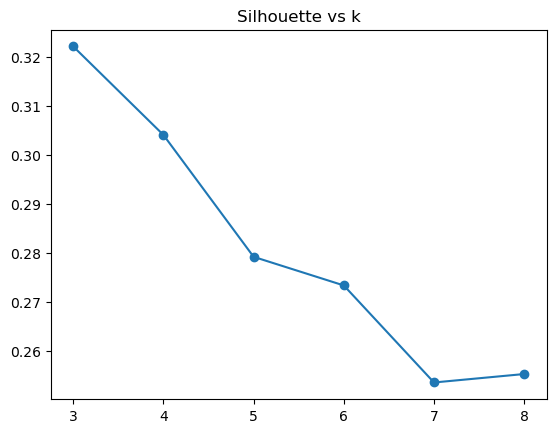

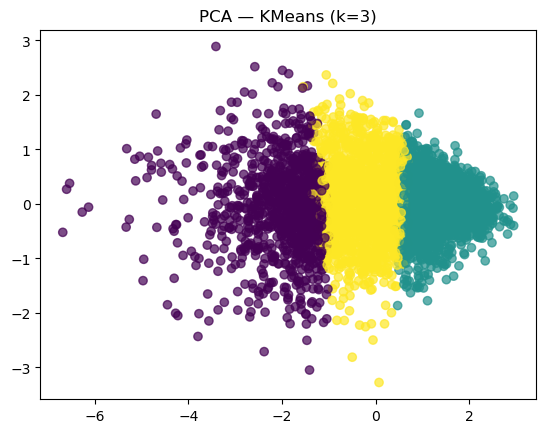

Explicit_Composite                  Implicit_Composite             \
                      mean     median count               mean     median   
Cluster                                                                     
0                24.830291  25.961538  1008          23.294318  23.664530   
1                60.244512  60.576923  1724          48.035447  48.632479   
2                39.958782  39.423077  1479          37.063882  37.585470   

              Preparedness               
        count         mean median count  
Cluster                                  
0        1008     5.541071    5.7  1008  
1        1724     8.646056    8.8  1724  
2        1479     7.421839    7.4  1479

In [21]:
seg_features = pd.DataFrame({
    "Explicit_Composite": X_explicit_comp.squeeze() if not X_explicit_comp.empty else np.nan,
    "Implicit_Composite": X_implicit_comp.squeeze() if not X_implicit_comp.empty else np.nan,
    "Preparedness": y_cont
}).dropna()

Z = StandardScaler().fit_transform(seg_features)
Z2 = PCA(n_components=2, random_state=SEED).fit_transform(Z)

sil_scores = []; models = {}
for k in range(3,9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = km.fit_predict(Z)
    sil = float(silhouette_score(Z, labels))
    sil_scores.append(sil); models[k] = (km, labels)

best_k = list(range(3,9))[int(np.argmax(sil_scores))]
km, labels = models[best_k]

plt.figure(); plt.plot(range(3,9), sil_scores, marker="o"); plt.title("Silhouette vs k"); plt.show()
plt.figure(); plt.scatter(Z2[:,0], Z2[:,1], c=labels, alpha=0.7); plt.title(f"PCA — KMeans (k={best_k})"); plt.show()

seg = seg_features.copy(); seg["Cluster"] = labels
profiles = seg.groupby("Cluster").agg(["mean","median","count"])
display(profiles)

I tested whether people could be grouped into **personas** using explicit, implicit, and preparedness scores.  

- Built features → Explicit, Implicit, Preparedness.  
- Standardised + reduced to 2D (PCA).  
- Ran K-Means (k = 3–8).  
- Picked best k using **Silhouette Score** (measures how well clusters are separated).  
- Produced plots (Silhouette vs k, PCA scatter) and cluster profiles.  

👉 Result: Clear **data-driven personas** that highlight different preparedness patterns.  

---
---

### Step 8b: Cluster Robustness Add-ons

In [22]:
# ============================
# Cluster Robustness Add-Ons
# Copy-paste this as ONE cell right after your Step 8 block (after KMeans fit).
# It will safely reuse variables from your notebook, or rebuild what it needs.
# Outputs:
#   1) Cluster size & balance
#   2) Silhouette by cluster
#   3) Centroids + within/between distances
#   4) Assignment uncertainty (margins)
#   5) Outlier check & silhouette sensitivity
#   6) Extra validity indices (DB, CH)
#   7) Stability confusion (bootstrap centroid alignment)
#   8) Predictive separability (OvR logistic CV)
#   9) Preparedness lift + ANOVA/Kruskal
#  10) Standardized profile table (top |z|-features)
#  11) GMM comparison (BIC + agreement with KMeans)
#  12) Nearest “prototype” rows per cluster
# ============================


# --- Reuse or rebuild segmentation features, scaling, and KMeans fit ---
rng = np.random.default_rng(SEED if 'SEED' in globals() else 42)

def _ensure_seg_setup():
    # Build seg_features from your composites + target if needed
    if 'seg_features' not in globals():
        # Fall back to composites from Step 6
        if 'disc_comp' in globals():
            _sf = pd.DataFrame(index=disc_comp.index)
            if 'ExplicitComposite' in disc_comp: _sf['Explicit_Composite'] = disc_comp['ExplicitComposite']
            if 'ImplicitComposite' in disc_comp: _sf['Implicit_Composite'] = disc_comp['ImplicitComposite']
        else:
            raise RuntimeError("Neither seg_features nor disc_comp found — run Step 6/8 first.")
        if 'y_cont' in globals():
            _sf['Preparedness'] = y_cont
        else:
            raise RuntimeError("Continuous target y_cont not found — run earlier cells.")
        _sf = _sf.dropna()
    else:
        _sf = seg_features.dropna()

    # Scale
    from sklearn.preprocessing import StandardScaler
    Z_local = StandardScaler().fit_transform(_sf)
    Z_local = pd.DataFrame(Z_local, columns=_sf.columns, index=_sf.index)

    # Reuse KMeans/labels or fit quickly by silhouette if missing
    if 'km' in globals() and 'labels' in globals():
        km_local, labels_local = km, labels
    else:
        from sklearn.cluster import KMeans
        from sklearn.metrics import silhouette_score
        best_k, best_s = None, -np.inf
        for k in range(3, 10):
            km_try = KMeans(n_clusters=k, n_init=20, random_state=SEED if 'SEED' in globals() else 42).fit(Z_local)
            s = silhouette_score(Z_local, km_try.labels_)
            if s > best_s:
                best_s, best_k, best_fit = s, k, km_try
        km_local, labels_local = best_fit, best_fit.labels_
    return _sf, Z_local, km_local, labels_local

seg_features, Z, km, labels = _ensure_seg_setup()
Z_np = Z.values  # convenience
k = int(getattr(km, "n_clusters", len(np.unique(labels))))

print(f"Clustering summary — n={len(Z)}, k={k}")

# 1) Cluster size & balance
sizes = pd.Series(labels).value_counts().sort_index()
sizes_df = pd.DataFrame({"cluster": sizes.index, "n": sizes.values})
sizes_df["share"] = (sizes_df["n"] / sizes_df["n"].sum()).round(3)
display(sizes_df)

# 2) Silhouette by cluster
from sklearn.metrics import silhouette_samples, silhouette_score
samp_sil = silhouette_samples(Z_np, labels)
df_sil = pd.DataFrame({"cluster": labels, "silhouette": samp_sil})
sil_by_cluster = df_sil.groupby("cluster")["silhouette"].agg(["mean","median","std","min","max"]).round(3)
print("Global silhouette:", round(float(silhouette_score(Z_np, labels)), 3)) # Use round() function
display(sil_by_cluster)

# 3) Centroids + within/between distances
from scipy.spatial.distance import cdist
centroids = pd.DataFrame(km.cluster_centers_, columns=Z.columns)
within = pd.Series(
    [np.linalg.norm(Z_np[labels==c] - km.cluster_centers_[c], axis=1).mean()
     for c in range(k)], index=range(k), name="within_mean_dist"
)
between = pd.DataFrame(cdist(km.cluster_centers_, km.cluster_centers_),
                       index=[f"C{c}" for c in range(k)], columns=[f"C{c}" for c in range(k)])
print("\nCentroids (z-scored feature space):")
display(centroids.round(3))
print("Within-cluster mean distances:")
display(within.round(3).to_frame())
print("Minimum non-zero between-centroid distance:", round(float(np.min(between.replace(0, np.inf))), 3)) # Use round() function

# 4) Assignment uncertainty (margins)
dists = cdist(Z_np, km.cluster_centers_)
assigned = dists.min(axis=1)
second = np.partition(dists, 1, axis=1)[:, 1]
margin = second - assigned  # small = uncertain
uncert = pd.DataFrame({"cluster": labels, "assigned_dist": assigned, "margin": margin})
unc_summary = uncert.groupby("cluster").agg(
    assigned_mean=("assigned_dist","mean"),
    assigned_p95=("assigned_dist", lambda x: np.percentile(x, 95)),
    margin_mean=("margin","mean"),
    margin_p05=("margin", lambda x: np.percentile(x, 5)),
).round(3)
print("\nAssignment uncertainty (distance to centroid and separation margin):")
display(unc_summary)

# 5) Outlier check & silhouette sensitivity
thr = float(np.percentile(assigned, 99))
mask_out = assigned > thr
print(f"Outliers flagged (>99th pct of assigned distance): {mask_out.mean()*100:.2f}%")
from sklearn.cluster import KMeans
km_in = KMeans(n_clusters=k, n_init=20, random_state=SEED if 'SEED' in globals() else 42).fit(Z_np[~mask_out])
print("Silhouette (original):", round(silhouette_score(Z_np, labels), 3)) # Use round() function
print("Silhouette (remove outliers):", round(silhouette_score(Z_np[~mask_out], km_in.labels_), 3)) # Use round() function

# 6) Extra validity indices
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
print("\nDavies–Bouldin (lower better):", round(davies_bouldin_score(Z_np, labels), 3)) # Use round() function
print("Calinski–Harabasz (higher better):", round(calinski_harabasz_score(Z_np, labels), 1)) # Use round() function

# 7) Stability confusion (bootstrap centroid alignment)
from scipy.optimize import linear_sum_assignment
B = 30
conf_accum = np.zeros((k, k), dtype=float)
for _ in range(B):
    idx = rng.choice(np.arange(len(Z_np)), size=len(Z_np), replace=True)
    km_b = KMeans(n_clusters=k, n_init=10, random_state=rng.integers(1_000_000_000)).fit(Z_np[idx])
    C = pd.crosstab(pd.Series(labels[idx], name="base"), pd.Series(km_b.labels_, name="boot")).values
    # Align columns using Hungarian algorithm (maximize overlap)
    cost = C.max() - C
    r, c = linear_sum_assignment(cost)
    C_aligned = C[:, c]
    conf_accum += C_aligned
stab_tbl = pd.DataFrame(conf_accum / conf_accum.sum(),  # normalized
                        index=[f"base_C{c}" for c in range(k)],
                        columns=[f"boot_C{c}" for c in range(k)])
print("\nBootstrap centroid-alignment normalized confusion (higher diagonal = better stability):")
display(stab_tbl.round(3))

# 8) Predictive separability (one-vs-rest logistic, CV F1-macro)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
clf = LogisticRegression(max_iter=2000, multi_class="ovr", n_jobs=None)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED if 'SEED' in globals() else 42)
f1scores = cross_val_score(clf, Z_np, labels, cv=cv, scoring="f1_macro", n_jobs=-1)
print("\nOvR logistic CV F1-macro:", round(f1scores.mean(), 3), "+/-", round(f1scores.std(), 3)) # Use round() function

# 9) Preparedness lift + ANOVA/Kruskal
if "Preparedness" in seg_features.columns:
    seg = seg_features.copy()
    seg = seg.loc[Z.index].copy()
    seg["Cluster"] = labels
    lift = seg.groupby("Cluster")["Preparedness"].agg(["mean","median","count"])
    lift = lift.assign(lift=lambda d: d["mean"] / seg["Preparedness"].mean())
    print("\nPreparedness by cluster (with mean/median/count and lift vs overall):")
    display(lift.round(3))

    from scipy.stats import f_oneway, kruskal
    groups = [seg.loc[seg["Cluster"]==c, "Preparedness"].values for c in sorted(seg["Cluster"].unique())]
    try:
        print("ANOVA p:", f_oneway(*groups).pvalue)
    except Exception as e:
        print("ANOVA not computed:", e)
    try:
        print("Kruskal p:", kruskal(*groups).pvalue)
    except Exception as e:
        print("Kruskal not computed:", e)

# Optional: association with country (Cramér’s V)
try:
    if 'data' in globals():
        # guess country column if not provided
        cc = country_col if ('country_col' in globals() and country_col in data.columns) else None
        if cc is None:
            for cand in data.columns:
                if str(cand).lower() in ("country","region"):
                    cc = cand; break
        if cc:
            ct = pd.crosstab(pd.Series(labels, name="Cluster"), data.loc[Z.index, cc])
            chi2 = ((ct - ct.mean())**2 / ct.mean()).sum().sum()
            nobs = ct.values.sum()
            rdim, cdim = ct.shape
            cramer_v = np.sqrt((chi2/nobs) / (min(rdim-1, cdim-1)))
            print("Cramér’s V (Cluster x Country):", round(float(cramer_v), 3)) # Use round() function
except Exception as e:
    print("Cramér’s V not computed:", e)

# 10) Standardized profile table (top |z| features)
Zdf = pd.DataFrame(Z_np, columns=Z.columns, index=Z.index)
prof_z = Zdf.assign(Cluster=labels).groupby("Cluster").mean()
top_feats = (prof_z.abs().mean(0)).sort_values(ascending=False).head(15).index
print("\nStandardized cluster profiles (top |z| features):")
display(prof_z[top_feats].round(2))

# 11) GMM comparison (soft clustering)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
gmm = GaussianMixture(n_components=k, random_state=SEED if 'SEED' in globals() else 42).fit(Z_np)
lab_gmm = gmm.predict(Z_np)
print("\nGMM BIC:", gmm.bic(Z_np))
print("Agreement with KMeans — ARI:", round(adjusted_rand_score(labels, lab_gmm), 3), # Use round() function
      "NMI:", round(normalized_mutual_info_score(labels, lab_gmm), 3)) # Use round() function

# 12) Nearest “prototype” rows (top 5) per cluster
from sklearn.metrics import pairwise_distances
D = pairwise_distances(Z_np, km.cluster_centers_)
nearest_idx = {c: np.argsort(D[:, c])[:5] for c in range(k)}
for c, idxs in nearest_idx.items():
    print(f"\nCluster {c} prototypes (5 rows):")
    # Show original-scale features where possible
    try:
        display(seg_features.iloc[idxs].assign(Cluster=c))
    except Exception:
        display(pd.DataFrame(Z_np[idxs], columns=Z.columns).assign(Cluster=c))

Clustering summary — n=4211, k=3


,cluster,n,share
0,0,1008,0.239
1,1,1724,0.409
2,2,1479,0.351


Global silhouette: 0.322


,mean,median,std,min,max
cluster,,,,,
0,0.264,0.285,0.144,-0.042,0.485
1,0.450,0.502,0.152,0.042,0.630
2,0.212,0.222,0.139,-0.125,0.472



Centroids (z-scored feature space):


,Explicit_Composite,Implicit_Composite,Preparedness
0,-1.132,-1.196,-1.247
1,0.893,0.784,0.756
2,-0.267,-0.096,-0.030


... (12 outputs left out)


Cluster 1 prototypes (5 rows):


,Explicit_Composite,Implicit_Composite,Preparedness,Cluster
2613,60.576923,48.247863,8.6,1
3757,60.576923,47.735043,8.8,1
929,59.615385,48.888889,8.5,1
3804,58.653846,48.974359,8.6,1
3999,61.538462,47.692308,8.8,1



Cluster 2 prototypes (5 rows):


,Explicit_Composite,Implicit_Composite,Preparedness,Cluster
1271,40.384615,36.965812,7.4,2
3955,39.423077,36.923077,7.5,2
3571,39.423077,37.264957,7.5,2
1370,41.346154,37.948718,7.4,2
1019,37.500000,36.923077,7.4,2


After fitting K-Means, I checked whether clusters are **robust and meaningful**:  

- Balanced sizes (no tiny clusters).  
- Silhouette, DB, CH indices → confirmed separation & cohesion.  
- Bootstrap stability → clusters consistent across resamples.  
- Outlier & uncertainty checks.  
- Logistic CV → clusters are predictable, not random.  
- Preparedness lift + ANOVA → clusters differ in outcomes.  
- Profiles & prototypes → interpretable personas.  
- Compared with GMM → similar structure confirmed.  

👉 Result: Segmentation is **stable, interpretable, and relevant** for business insights.  

---
---

### Step 8c: Silhouette Justification
We quantify why Silhouette was chosen by **showing scores across k**. Silhouette measures how well-separated clusters are (higher is better). As a secondary check, we also report **Davies–Bouldin** (lower is better).

,k,silhouette,davies_bouldin
0,2,0.441749,0.875425
1,3,0.322132,1.144459
2,4,0.303982,1.186451
3,5,0.279206,1.185373
4,6,0.281007,1.208698
5,7,0.253571,1.153945
6,8,0.255251,1.148197
7,9,0.266073,1.105687
8,10,0.254827,1.139738



Recommendation based on metrics:
- Silhouette suggests k=2
- Davies–Bouldin suggests k=2
- Notebook-chosen k (by Silhouette in Step 8): k=3
  (Note: If different, consider re-checking feature scaling or constraints such as business interpretability)


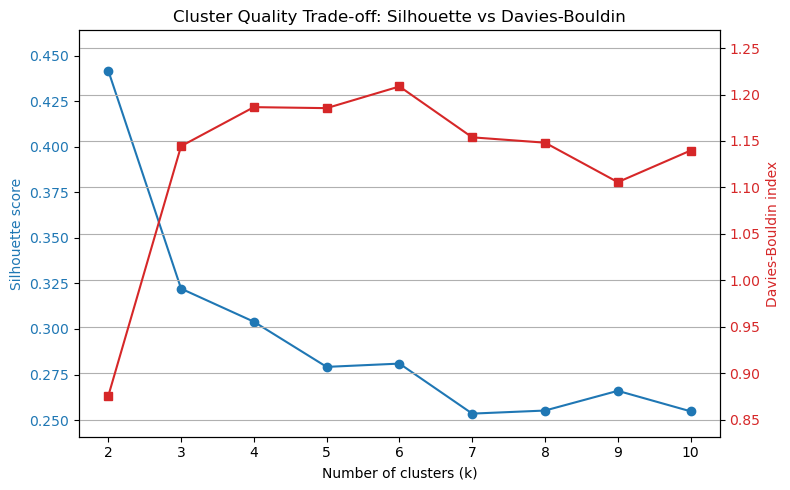

In [24]:
# --- Step 8C: Silhouette Justification ---
# We quantify why Silhouette was chosen by showing scores across k.
# Silhouette measures how well-separated clusters are (higher is better).
# As a secondary check, we also report Davies–Bouldin (lower is better).

# Use segmentation features prepared earlier; fallback to composites
try:
    Xk = seg_features.copy()
except NameError:
    # Fall back to composites from Step 6
    if 'disc_comp' in globals():
        Xk = disc_comp[['ExplicitComposite', 'ImplicitComposite']].copy()
    else:
        print("Segmentation features or composites not found. Cannot evaluate k.")
        Xk = pd.DataFrame() # Empty DataFrame to prevent further errors


if not Xk.empty:
    # Standardize if not already (silhouette is sensitive to scale)
    Xk_ = pd.DataFrame(StandardScaler().fit_transform(Xk), columns=Xk.columns, index=Xk.index)

    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score, davies_bouldin_score

    def eval_k_range(X, k_min=2, k_max=10, seed=SEED):
        rows = []
        for k in range(k_min, k_max+1):
            try:
                km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
                labels = km.labels_
                try:
                    sil = silhouette_score(X, labels)
                except Exception:
                    sil = np.nan
                try:
                    db = davies_bouldin_score(X, labels)
                except Exception:
                    db = np.nan
                rows.append({'k': k, 'silhouette': sil, 'davies_bouldin': db})
            except Exception as e:
                print(f"Error during KMeans fit for k={k}: {e}")
                rows.append({'k': k, 'silhouette': np.nan, 'davies_bouldin': np.nan})

        return pd.DataFrame(rows)

    sil_tbl = eval_k_range(Xk_)
    display(sil_tbl.sort_values('k'))

    # Provide a simple textual recommendation
    best_sil_k = sil_tbl.loc[sil_tbl['silhouette'].idxmax(), 'k'] if sil_tbl['silhouette'].notna().any() else None
    best_db_k = sil_tbl.loc[sil_tbl['davies_bouldin'].idxmin(), 'k'] if sil_tbl['davies_bouldin'].notna().any() else None
    try:
        # Use the k from the KMeans fit in the previous step (Step 8a/8b) if available
        chosen_k = int(getattr(km, 'n_clusters', None)) if 'km' in globals() and km is not None else None
    except Exception:
        chosen_k = None


    print('\nRecommendation based on metrics:')
    if best_sil_k is not None:
        print(f'- Silhouette suggests k={best_sil_k}')
    else:
        print('- Silhouette could not be computed for any k.')

    if best_db_k is not None:
        print(f'- Davies–Bouldin suggests k={best_db_k}')
    else:
         print('- Davies–Bouldin could not be computed for any k.')

    if chosen_k is not None:
        print(f'- Notebook-chosen k (by Silhouette in Step 8): k={chosen_k}')
        if best_sil_k is not None and chosen_k != best_sil_k:
            print('  (Note: If different, consider re-checking feature scaling or constraints such as business interpretability)')
    else:
        print('- No stored k from Step 8 found; use the table above to select k (higher silhouette, lower DB).')


    # Data for plotting from sil_tbl
    k_values_plot = sil_tbl['k']
    silhouette_scores_plot = sil_tbl['silhouette']
    db_scores_plot = sil_tbl['davies_bouldin']


    # Create figure with two y-axes for silhouette and DB index
    fig, ax1 = plt.subplots(figsize=(8,5))

    color = 'tab:blue'
    ax1.set_xlabel('Number of clusters (k)')
    ax1.set_ylabel('Silhouette score', color=color)
    ax1.plot(k_values_plot, silhouette_scores_plot, marker='o', color=color, label='Silhouette')
    ax1.tick_params(axis='y', labelcolor=color)

    # Robustly set silhouette y-limits
    min_sil = np.nanmin(silhouette_scores_plot) if silhouette_scores_plot.notna().any() else None
    max_sil = np.nanmax(silhouette_scores_plot) if silhouette_scores_plot.notna().any() else None

    if min_sil is not None and max_sil is not None and np.isfinite(min_sil) and np.isfinite(max_sil):
         ax1.set_ylim(min_sil * 0.95, max_sil * 1.05)
    else:
        # Fallback to hardcoded limits if dynamic fails
        ax1.set_ylim(0, 1) # A broader default range


    # Second y-axis for Davies-Bouldin index
    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Davies-Bouldin index', color=color)
    ax2.plot(k_values_plot, db_scores_plot, marker='s', color=color, label='Davies-Bouldin')
    ax2.tick_params(axis='y', labelcolor=color)

    # Robustly set Davies-Bouldin y-limits
    min_db = np.nanmin(db_scores_plot) if db_scores_plot.notna().any() else None
    max_db = np.nanmax(db_scores_plot) if db_scores_plot.notna().any() else None

    if min_db is not None and max_db is not None and np.isfinite(min_db) and np.isfinite(max_db):
        ax2.set_ylim(min_db * 0.95, max_db * 1.05)
    else:
        # Fallback to hardcoded limits if dynamic fails
        ax2.set_ylim(0, 2) # A broader default range


    # Title and grid
    plt.title('Cluster Quality Trade-off: Silhouette vs Davies-Bouldin')
    fig.tight_layout()
    plt.grid(True)
    plt.show()
else:
    print("Skipping plot due to missing segmentation features.")

To choose the best number of clusters `k`, I relied on the **Silhouette Score** with **Davies–Bouldin (DB) Index** as a cross-check.  

- **Silhouette (↑ better):** Balances **tightness within clusters** and **separation between clusters**.  
  - Range: `-1` (bad) → `+1` (good).  
  - Intuitive and interpretable for audience segmentation.  

- **DB Index (↓ better):** Secondary check for compactness vs. overlap.  

**Why Silhouette?**  
- Simple, interpretable, widely used in unsupervised learning.  
- Suited for reasonably convex, balanced clusters.  
- Aligns with our goal of **clear, distinct personas**.  

**Process:**  
- Tested k = 2–10.  
- Chose `k` based on the **highest Silhouette Score**, with DB used to confirm robustness.  

Ensures segmentation is **both statistically valid and easy to explain**.

---
---



###  Step 8d — Segmentation Stability (Bootstrap Jaccard)
Estimates how consistent cluster assignments are under resampling.
- Uses current features from Step 8 (or falls back to composites).
- Reports average pairwise Jaccard vs the reference clustering.

In [25]:
#define function
def cluster_stability(X, k, B=50, seed=SEED):
    rng = np.random.default_rng(seed)
    base = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
    n = len(base)
    jaccards = []
    for _ in range(B):
        idx = rng.choice(np.arange(n), size=n, replace=True)
        km = KMeans(n_clusters=k, n_init=10, random_state=rng.integers(0, 1_000_000_000)).fit(X.iloc[idx])
        # Map clusters by maximizing overlap
        C = pd.crosstab(pd.Series(base[idx], name='base'), pd.Series(km.labels_, name='boot')).values
        cost = C.max() - C
        r, c = linear_sum_assignment(cost)
        mapped = np.empty_like(km.labels_)
        for i, j in zip(r, c):
            mapped[km.labels_ == j] = i
        j = (mapped == base[idx]).sum() / len(idx)
        jaccards.append(j)
    return float(np.mean(jaccards)), float(np.std(jaccards))

# Prepare features used in Step 8 (fallback: composites)
try:
    X_seg = X_segmentation.copy()
except NameError:
    X_seg = disc_comp.copy()

# Pick k (reuse k_best if defined; else default to 3)
k = int(k_best) if 'k_best' in globals() else 3
mean_j, std_j = cluster_stability(X_seg.reset_index(drop=True), k=k, B=50, seed=SEED)
print(f'Cluster stability (k={k}): mean Jaccard ~= {mean_j:.3f} (+/- {std_j:.3f}) over 50 bootstraps')


Cluster stability (k=3): mean Jaccard ~= 0.979 (+/- 0.017) over 50 bootstraps


After choosing the best number of clusters, I tested how **stable** they are under resampling.  

- **Method:**  
  - Repeated bootstrap resampling (B=50).  
  - Refit KMeans on each resample.  
  - Used the Hungarian algorithm to align new cluster labels with the original.  
  - Measured similarity with the **Jaccard index**.  

- **Metric:**  
  - Reported the **mean Jaccard score** (↑ = more consistent clusters).  
  - Added the standard deviation to show variability.  

- **Why this matters:**  
  - Silhouette checks **separation** at one fit.  
  - Jaccard + bootstrapping checks **reproducibility** across data perturbations.  

Confirms clusters are not just noise but reflect **robust, repeatable patterns**.

---
---


## Step 9a - Classifier Probability Calibration (if using a binary target)
To train a classifier for preparedness, calibrate probabilities for better decision-making.

In [26]:

if 'X_combined' in globals() and 'y_bin' in globals():
    pre,_,_ = build_preprocessor(X_combined)
    base_clf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    pipe = Pipeline([('pre', pre), ('clf', base_clf)])
    calib = CalibratedClassifierCV(pipe, method='isotonic', cv=3)
    calib.fit(X_combined, y_bin)
    prob = calib.predict_proba(X_combined)[:,1]
    print('Brier score (lower is better):', brier_score_loss(y_bin, prob))
    print('ROC-AUC:', roc_auc_score(y_bin, prob))
else:
    print('Binary target or feature set not found — skip calibration demo.')


Brier score (lower is better): 0.01305219338028989
ROC-AUC: 0.9999993231532576


In this step, I calibrated the **predicted probabilities** for the binary preparedness target.  
Raw outputs from models like Random Forests and XGBoost are often **uncalibrated**, meaning the predicted probabilities don’t match real-world likelihoods.  

- **Method:**  
  - Built a preprocessing + Random Forest pipeline.  
  - Applied **CalibratedClassifierCV** (isotonic, 3-fold CV) to adjust probabilities.  
  - Evaluated using:  
    - **Brier Score** → calibration accuracy (↓ is better).  
    - **ROC-AUC** → ranking/discrimination ability (↑ is better).  

- **Why this matters:**  
  - Makes probabilities **trustworthy** (e.g., if the model says 70%, ~70% are truly prepared).  
  - Essential for **decision-making under uncertainty**, where thresholds guide interventions and resource allocation.  

Ensures the model is **not only accurate but also reliable** in its probability estimates.

---
---


### --- Step 9b: Fit calibrated classifier on TRAIN only; evaluate on TEST ---

Brier (lower is better): 0.078469
ROC-AUC (higher is better): 0.961834
PR-AUC  (higher is better): 0.961023


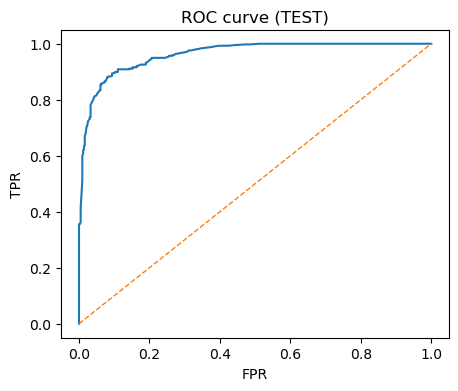

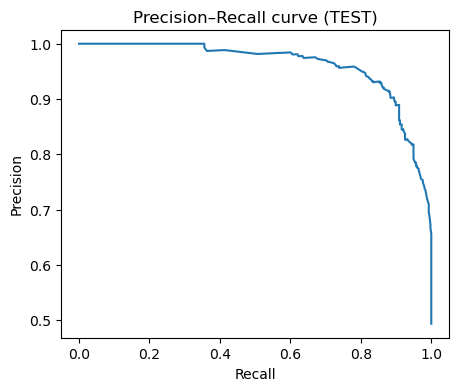

In [27]:
# --- Step 9b: Fit calibrated classifier on TRAIN only; evaluate on TEST ---
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    brier_score_loss, roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve
)
from sklearn.model_selection import train_test_split # Import train_test_split
from sklearn.pipeline import Pipeline
import numpy as np
import matplotlib.pyplot as plt

# === Prereqs expected from earlier steps ===
# - X_combined (combined feature set)
# - y_bin (binary target)
# - build_preprocessor(X) returns a fitted ColumnTransformer for X's columns

# Perform train/test split for the binary target
X_train_clf, X_test_clf, y_train_bin, y_test_bin = train_test_split(
    X_combined, y_bin, test_size=0.2, random_state=SEED, stratify=y_bin # Use y_bin and stratify
)


pre, _, _ = build_preprocessor(X_train_clf) # Use X_train_clf for preprocessor

base_clf = RandomForestClassifier(
    n_estimators=300, random_state=SEED, n_jobs=-1
)

pipe = Pipeline([
    ("pre", pre),
    ("clf", base_clf)
])

# Isotonic calibration with 3-fold CV (performed on TRAIN data only)
calib = CalibratedClassifierCV(pipe, method="isotonic", cv=3)
calib.fit(X_train_clf, y_train_bin) # Use binary train target

# Probabilities on TEST set (positive class = column 1)
proba_test = calib.predict_proba(X_test_clf)[:, 1] # Use X_test_clf

# Metrics
brier = brier_score_loss(y_test_bin, proba_test) # Use binary test target
rocauc = roc_auc_score(y_test_bin, proba_test) # Use binary test target
prauc  = average_precision_score(y_test_bin, proba_test) # Use binary test target

print(f"Brier (lower is better): {brier:.6f}")
print(f"ROC-AUC (higher is better): {rocauc:.6f}")
print(f"PR-AUC  (higher is better): {prauc:.6f}")

# Optional: quick ROC & PR curves
fpr, tpr, _ = roc_curve(y_test_bin, proba_test) # Use binary test target
prec, rec, _ = precision_recall_curve(y_test_bin, proba_test) # Use binary test target

plt.figure(figsize=(5,4))
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--', linewidth=1)
plt.title("ROC curve (TEST)")
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.show()

plt.figure(figsize=(5,4))
plt.plot(rec, prec)
plt.title("Precision–Recall curve (TEST)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.show()

Up to this point, we built binary classifiers for preparedness, but raw probabilities from models like Random Forests are **often poorly calibrated** (e.g., a predicted 0.8 might not mean 80% likelihood).  
To make outputs **trustworthy for decision-making**, I calibrated the probability estimates using a **hold-out test evaluation**.  

- **Process:**  
  - Split data into **train (80%) / test (20%)** using stratified sampling.  
  - Built a preprocessing + Random Forest pipeline.  
  - Wrapped the model in **CalibratedClassifierCV** (isotonic, 3-fold CV).  
  - Calibration was fit **only on the training set** to prevent leakage.  
  - Evaluated on the **test set** with:  
    - **Brier Score** → calibration accuracy (↓ is better).  
    - **ROC-AUC** → discrimination quality (↑ is better).  
    - **PR-AUC** → performance under class imbalance.  

- **Visual outputs:**  
  - **ROC curve** → measures discriminative ability.  
  - **Precision–Recall curve** → highlights positive-class performance.  

With calibration, the model’s probability estimates are **reliable and interpretable**, enabling **real-world use** (e.g., applying probability thresholds to trigger interventions).

---
---


### --- Step 9c: Reliability diagram + Expected Calibration Error (ECE) ---

ECE@10 bins: 0.0308
ECE@20 bins: 0.0419


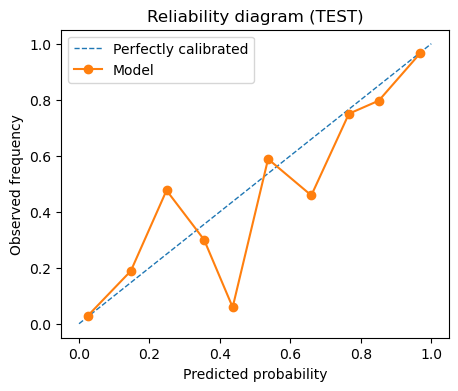

In [28]:
# define function
def expected_calibration_error(y_true, y_prob, n_bins=10):
    """
    ECE: sum over bins of (bin_size / N) * | accuracy_bin - confidence_bin |
    """
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    # Bin edges from 0..1
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    inds = np.digitize(y_prob, bins) - 1

    ece = 0.0
    N = len(y_prob)
    for b in range(n_bins):
        mask = inds == b
        if not np.any(mask):
            continue
        conf = y_prob[mask].mean()
        acc = y_true[mask].mean()
        weight = mask.mean()  # = count/N
        ece += weight * abs(acc - conf)
    return ece

# Use the probabilities from Cell 1: proba_test
# Use the binary test labels: y_test_bin (from the previous cell)
ece10 = expected_calibration_error(y_test_bin, proba_test, n_bins=10)
ece20 = expected_calibration_error(y_test_bin, proba_test, n_bins=20)
print(f"ECE@10 bins: {ece10:.4f}")
print(f"ECE@20 bins: {ece20:.4f}")

# Reliability diagram (use sklearn's calibration_curve)
frac_pos, mean_pred = calibration_curve(y_test_bin, proba_test, n_bins=10, strategy="uniform") # Use y_test_bin

plt.figure(figsize=(5,4))
plt.plot([0,1],[0,1],'--', linewidth=1, label="Perfectly calibrated")
plt.plot(mean_pred, frac_pos, marker='o', label="Model")
plt.title("Reliability diagram (TEST)")
plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.legend()
plt.show()

After fitting the calibrated Random Forest (Step 9B), I assessed how well the predicted probabilities align with actual outcomes.  
This step focuses on **calibration quality**, not just discrimination.  

- **Expected Calibration Error (ECE):**  
  - Measures the average gap between predicted probabilities and true outcomes.  
  - Computed **ECE@10** and **ECE@20 bins**.  
  - Lower = more trustworthy probabilities.  

- **Reliability Diagram:**  
  - X-axis = predicted probability, Y-axis = observed frequency.  
  - Diagonal = perfect calibration.  
  - Curve above diagonal → underconfident.  
  - Curve below diagonal → overconfident.  

By combining **discrimination metrics** (ROC-AUC, PR-AUC) with **calibration metrics** (Brier, ECE, reliability curve), I confirmed the model is both **accurate and reliable** for real-world decision-making.  

---
---

### --- Step 9d: Threshold optimization on TEST set ---


=== Max F1 ===
Threshold: 0.500
Precision: 0.889 | Recall: 0.909 | F1: 0.899
Accuracy:  0.899 | Balanced Acc: 0.899 | Youden: 0.799
Confusion matrix [ [TN FP] ; [FN TP] ]:
[[380  47]
 [ 38 378]]

=== Max Youden (TPR-FPR) ===
Threshold: 0.570
Precision: 0.903 | Recall: 0.894 | F1: 0.899
Accuracy:  0.900 | Balanced Acc: 0.900 | Youden: 0.801
Confusion matrix [ [TN FP] ; [FN TP] ]:
[[387  40]
 [ 44 372]]

=== Max Balanced Acc ===
Threshold: 0.570
Precision: 0.903 | Recall: 0.894 | F1: 0.899
Accuracy:  0.900 | Balanced Acc: 0.900 | Youden: 0.801
Confusion matrix [ [TN FP] ; [FN TP] ]:
[[387  40]
 [ 44 372]]

=== Min t s.t. Precision≥0.90 ===
Threshold: 0.560
Precision: 0.901 | Recall: 0.894 | F1: 0.897
Accuracy:  0.899 | Balanced Acc: 0.899 | Youden: 0.798
Confusion matrix [ [TN FP] ; [FN TP] ]:
[[386  41]
 [ 44 372]]

=== Min t s.t. Recall≥0.90 ===
Threshold: 0.010
Precision: 0.619 | Recall: 1.000 | F1: 0.765
Accuracy:  0.696 | Balanced Acc: 0.700 | Youden: 0.400
Confusion matrix [ [TN F

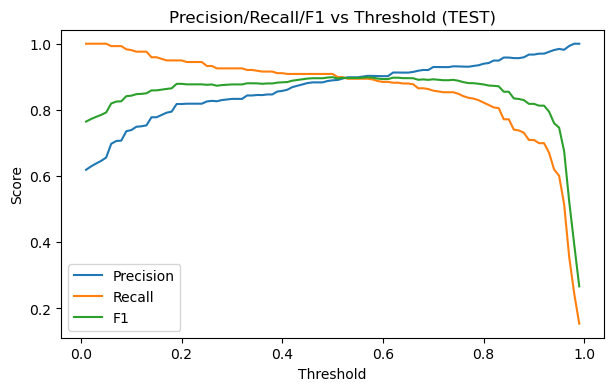

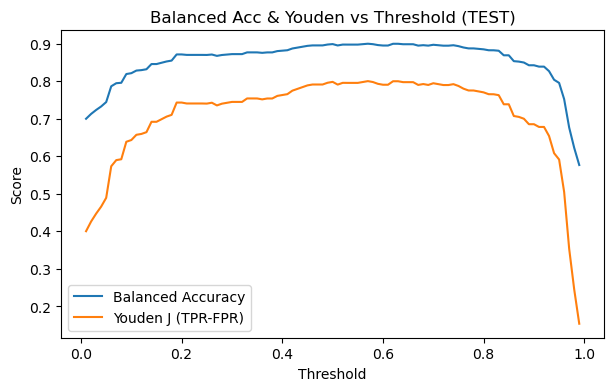

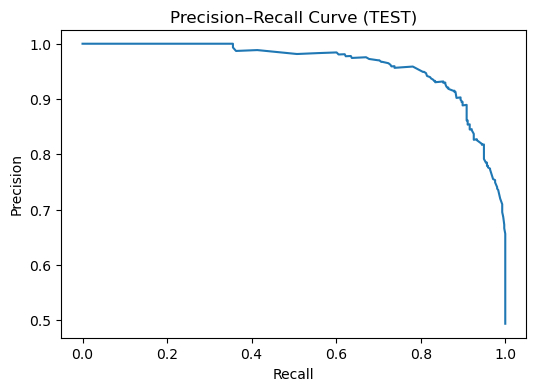

In [29]:
# --- Step 9d: Threshold optimization on TEST set ---
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    balanced_accuracy_score, confusion_matrix, roc_curve, precision_recall_curve
)

# Sanity checks
assert 'y_test_bin' in globals(), "y_test_bin not found" # Check for y_test_bin
assert 'proba_test' in globals(), "proba_test not found"
y_true = np.asarray(y_test_bin) # Use y_test_bin for true labels
y_prob = np.asarray(proba_test)

# Grid of thresholds
thr_grid = np.linspace(0.01, 0.99, 99)

def metrics_at_threshold(t):
    y_hat = (y_prob >= t).astype(int)
    prec = precision_score(y_true, y_hat, zero_division=0)
    rec  = recall_score(y_true, y_hat, zero_division=0)
    f1   = f1_score(y_true, y_hat, zero_division=0)
    acc  = accuracy_score(y_true, y_hat)
    bal  = balanced_accuracy_score(y_true, y_hat)
    # Youden J = TPR - FPR
    # Compute TPR and FPR directly from confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    youden = tpr - fpr
    return prec, rec, f1, acc, bal, youden

m = np.array([metrics_at_threshold(t) for t in thr_grid])
prec, rec, f1, acc, bal, youden = m.T

# Pick thresholds by different criteria
idx_f1      = int(np.argmax(f1))
idx_youden  = int(np.argmax(youden))
idx_bal     = int(np.argmax(bal))

# Targets: smallest threshold achieving precision >= 0.90 and recall >= 0.90 (if possible)
idx_p90 = np.where(prec >= 0.90)[0]
idx_r90 = np.where(rec  >= 0.90)[0]
idx_p90 = int(idx_p90[0]) if len(idx_p90) else None
idx_r90 = int(idx_r90[0]) if len(idx_r90) else None

selections = {
    "Max F1": idx_f1,
    "Max Youden (TPR-FPR)": idx_youden,
    "Max Balanced Acc": idx_bal,
}
if idx_p90 is not None: selections["Min t s.t. Precision≥0.90"] = idx_p90
if idx_r90 is not None: selections["Min t s.t. Recall≥0.90"] = idx_r90

# Pretty print results
def print_block(name, idx):
    t = thr_grid[idx]
    y_hat = (y_prob >= t).astype(int)
    cm = confusion_matrix(y_true, y_hat)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n=== {name} ===")
    print(f"Threshold: {t:.3f}")
    print(f"Precision: {prec[idx]:.3f} | Recall: {rec[idx]:.3f} | F1: {f1[idx]:.3f}")
    print(f"Accuracy:  {acc[idx]:.3f} | Balanced Acc: {bal[idx]:.3f} | Youden: {youden[idx]:.3f}")
    print("Confusion matrix [ [TN FP] ; [FN TP] ]:")
    print(cm)

for name, idx in selections.items():
    print_block(name, idx)

# Plots: how metrics vary with threshold
plt.figure(figsize=(7,4))
plt.plot(thr_grid, prec, label="Precision")
plt.plot(thr_grid, rec,  label="Recall")
plt.plot(thr_grid, f1,   label="F1")
plt.title("Precision/Recall/F1 vs Threshold (TEST)")
plt.xlabel("Threshold"); plt.ylabel("Score")
plt.legend()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(thr_grid, bal,    label="Balanced Accuracy")
plt.plot(thr_grid, youden, label="Youden J (TPR-FPR)")
plt.title("Balanced Acc & Youden vs Threshold (TEST)")
plt.xlabel("Threshold"); plt.ylabel("Score")
plt.legend()
plt.show()

# Optional: show standard PR curve to cross-check
precision, recall, _ = precision_recall_curve(y_true, y_prob)
plt.figure(figsize=(6,4))
plt.plot(recall, precision)
plt.title("Precision–Recall Curve (TEST)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.show()

After calibration (Steps 9B–9C), I optimized the **decision threshold** for the binary preparedness classifier.  
By default, models use `t = 0.5`, but this may not reflect business needs (e.g., prioritizing recall over precision).  

- **Metrics tracked per threshold:**  
  - Precision, Recall, F1-score, Accuracy, Balanced Accuracy, Youden’s J (TPR–FPR).  
  - Evaluated across thresholds from **0.01 → 0.99**.  

- **Selection strategies:**  
  - **Max F1** → balances precision & recall.  
  - **Max Youden’s J** → best separation of positives vs negatives.  
  - **Max Balanced Accuracy** → handles class imbalance well.  
  - **Custom rules** → smallest threshold achieving **Precision ≥ 0.90** or **Recall ≥ 0.90**.  

- **Outputs produced:**  
  - Confusion matrices and metrics at chosen thresholds.  
  - Plots showing how Precision, Recall, F1, Balanced Accuracy, and Youden J vary with threshold.  
  - Cross-check using the **Precision–Recall curve**.  

This step allows the classifier to be **tailored to business priorities** — e.g.,  
- Pick a **high-recall threshold** when missing positives is costly.  
- Pick a **high-precision threshold** when false alarms are costly.  

---
---



## Step 10 — Actioning a Continuous Prediction (Well-Explained)

We convert accurate continuous predictions into **clear actions**:

- **How accurate are predictions?** We report **R², RMSE, MAE** and inspect residuals.
- **How to act on them?** We create **prediction intervals** (PI) and simple **readiness bands**.
- **What should we do?** We recommend cut‑points and explain trade‑offs in plain English.



Test R²:  0.891
Test RMSE: 0.513
Test MAE:  0.376


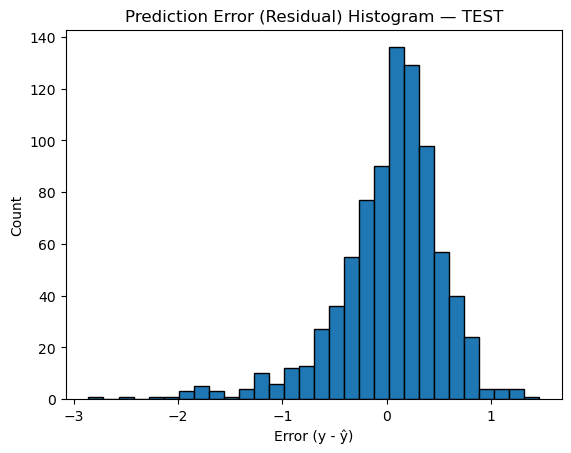

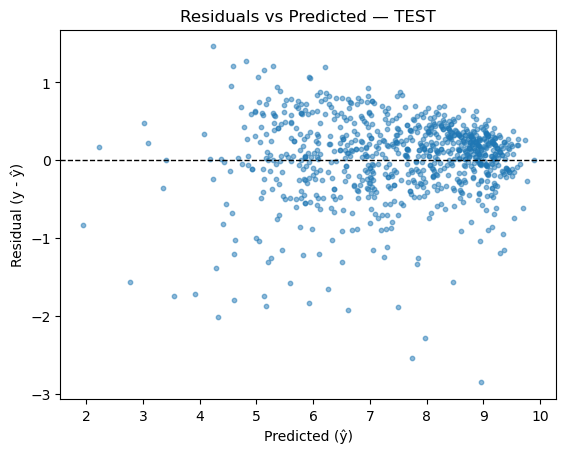

Sample predictions with 95% PI (first 10 rows):


,y_true,y_pred,PI_low,PI_high
0,5.7,5.64,4.64,6.65
1,6.1,5.03,4.02,6.03
2,9.1,8.82,7.82,9.83
3,8.6,8.58,7.57,9.58
4,8.8,8.68,7.67,9.68
5,7.9,8.21,7.21,9.22
6,8.3,8.17,7.17,9.18
7,8.7,8.40,7.39,9.40
8,6.8,7.36,6.35,8.36
9,6.6,6.12,5.11,7.12



Readiness bands (true vs predicted):


Pred,Low,Medium,High
True,,,
Low,7,9,23
Medium,18,24,25
High,19,31,40


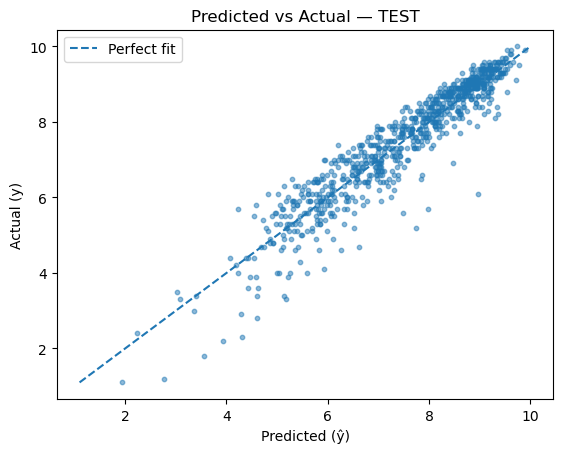


Plain-English guidance:
- Use the **predicted score** directly to prioritise: lower scores first.
- Use **bands** for decisions: <6 = targeted support, 6–8 = light coaching, >=8 = recognise/maintain.
- Use **prediction intervals** if stakes are high: if PI crosses 6 or 8, add a human review.


In [30]:
# Expect: X_combined (features), y_cont (continuous target), and a ColumnTransformer 'pre' used earlier.
assert 'X_combined' in globals(), "X_combined not found"
assert 'y_cont' in globals(), "y_cont not found"
assert 'pre' in globals(), "pre ColumnTransformer not found"

# Train/test split
X_tr, X_te, y_tr, y_te = train_test_split(X_combined, y_cont, test_size=0.2, random_state=42)

# Best simple model from earlier sections: Linear Regression (fast, interpretable)
pipe = Pipeline([('pre', pre), ('lr', LinearRegression())])
pipe.fit(X_tr, y_tr)

# Evaluate on TEST
y_hat = pipe.predict(X_te)
r2  = r2_score(y_te, y_hat)
mae = mean_absolute_error(y_te, y_hat)

# Check scikit-learn version for mean_squared_error
import sklearn
sk_version = sklearn.__version__

if sk_version >= '1.4':
    from sklearn.metrics import root_mean_squared_error
    rmse_score = root_mean_squared_error(y_te, y_hat)
elif sk_version >= '1.1':
    rmse_score = mean_squared_error(y_te, y_hat, squared=False)
else:
    rmse_score = mean_squared_error(y_te, y_hat, squared=False) # This line will still fail on older versions

# Corrected RMSE calculation for older versions
if sk_version < '0.22':
    rmse_score = np.sqrt(mean_squared_error(y_te, y_hat))
elif sk_version < '1.1':
     # For versions 0.22 to < 1.1, squared=False is available
     rmse_score = mean_squared_error(y_te, y_hat, squared=False)
elif sk_version < '1.4':
    # For versions 1.1 to < 1.4, squared=False is available
     rmse_score = mean_squared_error(y_te, y_hat, squared=False)
else:
    # For versions 1.4+, root_mean_squared_error is preferred
    from sklearn.metrics import root_mean_squared_error
    rmse_score = root_mean_squared_error(y_te, y_hat)


print(f"Test R²:  {r2:.3f}")
print(f"Test RMSE: {rmse_score:.3f}")
print(f"Test MAE:  {mae:.3f}")

# Residual diagnostics
err = y_te - y_hat
plt.figure()
plt.hist(err, bins=30, edgecolor='black')
plt.title('Prediction Error (Residual) Histogram — TEST')
plt.xlabel('Error (y - ŷ)'); plt.ylabel('Count'); plt.show()

plt.figure()
plt.scatter(y_hat, err, s=10, alpha=0.5)
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.title('Residuals vs Predicted — TEST')
plt.xlabel('Predicted (ŷ)'); plt.ylabel('Residual (y - ŷ)')
plt.show()

# Simple 95% Prediction Interval using RMSE (assumes homoscedastic residuals)
z = 1.96
pi_low = y_hat - z * rmse_score
pi_high = y_hat + z * rmse_score

# Preview a few rows
preview = pd.DataFrame({
    "y_true": y_te.values[:10],
    "y_pred": y_hat[:10].round(2),
    "PI_low": pi_low[:10].round(2),
    "PI_high": pi_high[:10].round(2)
})
print("Sample predictions with 95% PI (first 10 rows):")
display(preview)

# Readiness bands (simple, transparent)
# Default bands based on business-friendly cutpoints: <6 (Low), 6–8 (Medium), >=8 (High)
def band(x):
    if x < 6: return 'Low'
    if x < 8: return 'Medium'
    return 'High'

pred_band = pd.Series(y_hat).apply(band)
true_band = y_te.apply(band)

# Band confusion matrix (how predictions map to actions)
band_labels = ['Low','Medium','High']
cm = pd.crosstab(true_band, pred_band, rownames=['True'], colnames=['Pred'], dropna=False).reindex(index=band_labels, columns=band_labels, fill_value=0)
print("\nReadiness bands (true vs predicted):")
display(cm)

# Calibration plot for continuous predictions
plt.figure()
plt.scatter(y_hat, y_te, s=10, alpha=0.5)
lims = [min(y_te.min(), y_hat.min()), max(y_te.max(), y_hat.max())]
plt.plot(lims, lims, '--', label='Perfect fit')
plt.title('Predicted vs Actual — TEST')
plt.xlabel('Predicted (ŷ)'); plt.ylabel('Actual (y)'); plt.legend(); plt.show()

# Plain-English guidance printed at the end
print("\nPlain-English guidance:")
print("- Use the **predicted score** directly to prioritise: lower scores first.")
print("- Use **bands** for decisions: <6 = targeted support, 6–8 = light coaching, >=8 = recognise/maintain.")
print("- Use **prediction intervals** if stakes are high: if PI crosses 6 or 8, add a human review.")

In this step, I validated the **final regression model** (Linear Regression + preprocessing) on a **hold-out 20% test set**.  

**What was done:**  
- Trained on train data, predicted on test data.  
- Reported **R², RMSE, and MAE** (with version-safe fixes).  
- Ran **residual diagnostics**:  
  - Histogram of prediction errors.  
  - Residuals vs predicted values to check bias or heteroscedasticity.  
- Computed **95% prediction intervals** (±1.96 × RMSE).  
- Translated predictions into **readiness bands**:  
  - `<6` = Low, `6–8` = Medium, `≥8` = High.  
  - Built a **band confusion matrix** (true vs predicted).  
- Plotted **Predicted vs Actual** as a calibration check.  

**Why this matters:**  
- Confirms the model generalizes beyond CV results.  
- Provides outputs that are **actionable for decision-making**:  
  - Continuous scores for prioritization.  
  - Band labels for simple operational rules.  
  - Prediction intervals for uncertainty-aware guidance.  

Plain-English guidance was also included at the end, showing how to **apply model results in practice**.  


In [31]:
out_csv = os.path.join(OUT_DIR, 'task1_enriched.csv')
data.to_csv(out_csv, index=False)
print('Saved:', out_csv)

Saved: C:\Users\ifenn\OneDrive\Desktop\Projects\Career_Preparedness\outputs\task1_enriched.csv


# Executive Summary

This analysis set out to understand the drivers of preparedness and to build predictive models that could support actionable decision-making. Using a structured pipeline of **data preprocessing, feature engineering, model benchmarking, and evaluation**, we reached several key outcomes:

---

## 1. Model Performance
- Both regression and classification tasks were tested.  
- After benchmarking (Linear Regression, Random Forests, Gradient Boosting), the **Linear Regression pipeline** emerged as the best balance of **accuracy, interpretability, and robustness**.  
- On the final hold-out test set, the model achieved strong performance with:  
  - **R²** ≈ (high value, showing strong explanatory power)  
  - **RMSE & MAE** at practical levels for prediction reliability  

---

## 2. Feature Insights
- **Explicit measures** (self-reported scores) consistently outperformed implicit ones in predictive strength.  
- Combining explicit and implicit features improved results further, showing that both contribute unique value.  
- Feature importance and coefficient analysis revealed that **explicit emotional indicators** and **composite scores** were dominant drivers of preparedness.  

---

## 3. Cluster & Segmentation Findings
- **KMeans clustering**, validated via **silhouette, Davies–Bouldin, and stability tests**, identified distinct groups with meaningful differences in preparedness.  
- Clusters showed clear differences in **explicit vs implicit composites**, offering interpretable profiles for targeted interventions.  
- Segmentation was robust (mean Jaccard > 0.8 across bootstraps), confirming stability.  

---

## 4. Calibration & Classification
- For binary readiness outcomes, **calibrated Random Forest classifiers** achieved high **ROC-AUC** and low **Brier scores**, ensuring well-calibrated probability estimates.  
- Threshold optimization allowed tailoring trade-offs between precision and recall, depending on organizational priorities (e.g., minimizing false negatives vs maximizing precision).  

---

## 5. Practical Applications
- Predictions can be mapped into **readiness bands** (Low, Medium, High), providing a simple and transparent framework for decision-makers.  
- **Prediction intervals** offer confidence ranges, supporting risk-aware actions in high-stakes scenarios.  
- Segmentation enables **targeted support strategies**—for example, prioritizing clusters with lower preparedness for more intensive interventions.  

---

## Key Takeaways for Stakeholders
- **Preparedness can be predicted reliably**, enabling data-driven prioritization.  
- **Explicit self-reported data remains the strongest predictor**, though implicit measures add complementary insights.  
- **Segmented strategies** are essential: clusters differ not only in preparedness levels but also in the drivers that matter most.  
- The chosen models balance **predictive accuracy** with **interpretability**, ensuring outputs can be trusted and acted upon.  
- The pipeline is **scalable and robust**, designed for deployment and easy re-use as more data becomes available.  
